In [299]:
#subject_folder = r"C:/dummy/path/sub-XX"
#subject_folder = "C:/Yoyi/BIDS Dataset/sourcedata/sub-02"
Preprocessed_Data_Folder = r"C:\Yoyi\Preprocessed Data"

# Import Libraries

In [300]:
from BCI2kReader import BCI2kReader as b2k  # Library for reading BCI2000 files
import os                                   # Library to read file directories
import numpy as np                          # Library for array management
import pandas as pd                         # Library for managing data in tables
import matplotlib.pyplot as plt             # Library for plotting data
import math                                 # Library for mathematical operations and constants
import mne                                  # EEG/EMG processing library

# Defines

In [301]:
FS = 2400
TRIAL_SAMPLES = FS * 10
TRIALS_PER_RUN = 32

output_dir = os.path.join(os.getcwd(), "output")

# Testing

In [302]:
# import os
# import math
# import numpy as np
# import pandas as pd
# import mne
# from BCI2kReader import BCI2kReader as b2k

# import glob
# import re

# # ==============================================================================
# # 1. PARÁMETROS DEL EXPERIMENTO (Actualizados)
# # ==============================================================================
# data_dir = r"C:\Yoyi\Raw Data"

# # Ahora mapeamos los IDs reales a las condiciones lógicas para no perder el orden
# subjects = ['5']#, '6'] # IDs exactos usados en el nombre del archivo
# sessions_map = {
#     '001': 'stim', # Ajusta qué sesión corresponde a qué condición
#     '002': 'sham'
# }

# FS = 2400
# trialSamples = FS * 10
# trials_per_run = 32
# min_file_size_bytes = 69000000 #69 * 1024 * 1024  # 69 MB en bytes

# analyze_during = True 

# # ==============================================================================
# # 2. ESCÁNER INTELIGENTE DE DIRECTORIO
# # ==============================================================================
# def scan_and_categorize_runs(session_folder, subject_id, session_id):
#     """
#     Escanea la carpeta, filtra por tamaño, ordena por tiempo y clasifica 
#     los archivos .dat en bloques lógicos evadiendo tu complejo esquema de nombres.
#     """
#     # Patrón de búsqueda: ej. "1S001R*.dat"
#     pattern = os.path.join(session_folder, f"{subject_id}S{session_id}R*.dat")
#     all_files = glob.glob(pattern)
    
#     # Expresión regular para capturar el Run (2 dígitos) y el Timestamp
#     regex = re.compile(r"R(\d{2})\(([\d\-]+)\)\.dat$")
    
#     valid_files = []
    
#     for filepath in all_files:
#         # Filtro estricto de tamaño
#         if os.path.getsize(filepath) <= min_file_size_bytes:
#             continue
            
#         match = regex.search(filepath)
#         if match:
#             run_num = int(match.group(1))
#             timestamp = match.group(2)
#             valid_files.append((run_num, timestamp, filepath))
            
#     # El ordenamiento alfanumérico del timestamp (YYYY-MM-DD-HH-MM-SS) nos da el orden cronológico exacto
#     valid_files.sort(key=lambda x: x[1])
    
#     # Clasificación por bloques
#     blocks = {'pre': [], 'during': [], 'post': []}
    
#     r02_files = [f for r, t, f in valid_files if r == 2]
    
#     # Lógica de exclusión e inclusión estricta
#     for r, t, filepath in valid_files:
#         if r in [1, 11]:
#             continue # Descartar basales
#         elif 3 <= r <= 6:
#             blocks['pre'].append(filepath)
#         elif 7 <= r <= 10:
#             blocks['post'].append(filepath)
            
#     # Lógica especial para los runs "2"
#     if len(r02_files) > 1:
#         # R02[0] es el training (se ignora automáticamente al tomar a partir del índice 1)
#         blocks['during'] = r02_files #r02_files[1:5] # Aseguramos tomar sólo los 4 runs de estimulación

#     return blocks

# # -------------------------------
# # LoadingBCI2000Data
# def LoadingBCI2000Data(filename):

#     # -------------------------------
#     # Load BCI2000 Data
#     with b2k.BCI2kReader(filename) as test: # Reading the .dat information
#         my_signals, my_states=test.readall() 
    
#     # -------------------------------
#     # Creating DataFrame
#     cols = test.parameters['ChannelNames'] # Headings of the DataFrame and name of the registered channels
#     data = pd.DataFrame(my_signals.T, columns=cols) # Adding EEG/EMG data to DataFrame
#     data['FE_Motor'] = my_states['XCoordinates'][0] # Adding FE Motor data
#     data['RUD_Motor'] = my_states['YCoordinates'][0] # Adding RUD Motor data
#     data['TrialInit'] = my_states['TrialInitStamp'][0] # Adding Trial Init event
#     data['AllTargetShow'] = my_states['AllTargetShowStamp'][0] # Adding All Target Show event
#     data['InitMov'] = my_states['TrialInitMovStamp'][0] # Adding Init Movement event
#     data['InitReturnMov'] = my_states['TrialEndMovStamp'][0] # Adding Init Return Movement event
#     data['CurrentTarget'] = my_states['CurrentTarget'][0] * 0 # Adding Current Target event (initialized to zero)

#     init = data.loc[my_states['TrialInitStamp'][0] == 1].index[0] # Finding the first Trial Init event

#     if init > trialSamples:
#         init = init - trialSamples
    
#     # # Cutting the data to start from the first Trial Init event
#     data = data.iloc[init:]

#     # # Resetting the index
#     data.reset_index(drop=True, inplace=True)

#     targets = np.zeros(shape = (trials_per_run), dtype=int)

#     # filling the targets array
#     for x in range(trials_per_run):
#         targets [x] = my_states['CurrentTarget'][0][x*trialSamples + int(trialSamples/2) + FS] # middle of the trial + 1 sec (to make sure the target is already shown), during register the event was set at the middle of the trial.
#         data.loc[x*trialSamples,'CurrentTarget'] = targets [x]    

#     # data2D matrix holds all data from the 40 trials in 2D format (channels x samples), 23 channels: 8 EEG + 8 EMG + FE_Motor + RUD_Motor + 5 events
#     data2D = np.zeros(shape=(23,trialSamples*trials_per_run), dtype=np.float32)
#     data2D[:,:] = data.iloc[0:trialSamples*trials_per_run].transpose()

#     data2D[16,:] = ConvertMotorEncoderToUIDisplacement(motor= "FE", RawData= data2D[16,:])
#     data2D[17,:] = ConvertMotorEncoderToUIDisplacement(motor= "RUD", RawData= data2D[17,:])

#     for i in range(0,11):
#         data2D[16,i] = data2D[16,10];
#         data2D[17,i] = data2D[17,10];

#     return data2D, cols, targets

# # -------------------------------
# # ConvertMotorEncoderToUIDisplacement
# def ConvertMotorEncoderToUIDisplacement(motor, RawData):
#     #Convert data to Rads 
#     output = ((RawData * 25) /65535) - 12.5

#     if motor == "FE":
#         #Convert Rads to Degrees
#         output = output*180/math.pi
#         #UI Scaling convertion
#         for i in range(len(output)):
#             if output[i] >= 0:
#                 output[i] = output[i] * 1.543
#             else:
#                 output[i] = output[i] * 1.559

#     elif motor == "RUD":
#         #Convert Rads to Degrees
#         output = output*-180/math.pi
#         #UI Scaling convertion
#         for i in range(len(output)):
#             if output[i] <= 0:
#                 output[i] = output[i] * 2.3913
#             else:
#                 output[i] = output[i] * 4.866
#     else:
#         return 0
    
#     return output

# # ==============================================================================
# # NUEVA FUNCIÓN: LECTURA DE METADATOS
# # ==============================================================================
# def load_session_mapping(csv_path):
#     """
#     Lee el archivo CSV de metadatos y genera un diccionario anidado:
#     { 'subject_id': { 'session_id': 'condition' } }
#     """
#     # Leer como string para evitar que pandas convierta '001' en el entero 1
#     df = pd.read_csv(csv_path, dtype=str) 
    
#     mapping = {}
#     for _, row in df.iterrows():
#         sub = row['subject_id']
#         ses = row['session_id']
#         cond = row['condition']
        
#         if sub not in mapping:
#             mapping[sub] = {}
#         mapping[sub][ses] = cond
        
#     return mapping

# # ==============================================================================
# # 3. BUCLE PRINCIPAL DE PROCESAMIENTO MNE
# # ==============================================================================

# metadata_file = data_dir + r"\metadata.csv" # Ruta a tu nuevo archivo
# dynamic_sessions_map = load_session_mapping(metadata_file)

# # Las condiciones analíticas finales (para la estructura de salida)
# conditions = ['stim', 'sham']

# # Reestructuramos el diccionario maestro para que dependa de la condición, no del número de sesión
# results_epochs = {sub: {cond: {'pre': {}, 'during': {}, 'post': {}} for cond in conditions} for sub in subjects}

# for subject in subjects:
#     print(f"\nProcesando Sujeto: {subject}")

#     if subject not in dynamic_sessions_map:
#         print(f"  [!] Sujeto {subject} no encontrado en el archivo de metadatos. Saltando.")
#         continue
        
#     # Iteramos sobre las sesiones reales que tiene el sujeto en el CSV
#     for session_id, condition_name in dynamic_sessions_map[subject].items():
#         print(f"  Sesión [{session_id}]: Condición decodificada -> {condition_name.upper()}")
        
#         session_folder = os.path.join(data_dir, subject, session_id) 
        
#         if not os.path.exists(session_folder):
#             print(f"    [!] Directorio no encontrado: {session_folder}")
#             continue

#         dynamic_blocks = scan_and_categorize_runs(session_folder, subject, session_id)
        
#         for block_name, filepaths in dynamic_blocks.items():
#             if not filepaths:
#                 continue
                
#             if block_name == 'during' and not analyze_during:
#                 continue
            
#             print(f"    -> Procesando bloque: {block_name} ({len(filepaths)} runs detectados)")
    
#     # for session_id, session_name in sessions_map.items():
#     #     print(f"  Sesión [{session_id}]: {session_name.upper()}")
        
#     #     # Asumiendo que las carpetas están nombradas por los IDs crudos. 
#     #     # Modifica esto si tu estructura de carpetas usa 'stim'/'sham' directamente.
#     #     session_folder = os.path.join(data_dir, subject, session_id) 
        
#     #     if not os.path.exists(session_folder):
#     #         print(f"    [!] Directorio no encontrado: {session_folder}")
#     #         continue

#     #     # Generar bloques dinámicamente con las rutas absolutas exactas
#     #     dynamic_blocks = scan_and_categorize_runs(session_folder, subject, session_id)
        
#     #     for block_name, filepaths in dynamic_blocks.items():
#     #         if not filepaths:
#     #             print(f"    -> Bloque '{block_name}' vacío o sin archivos válidos. Saltando.")
#     #             continue
                
#     #         if block_name == 'during' and not analyze_during:
#     #             print(f"    -> Saltando bloque '{block_name}' intencionalmente...")
#     #             continue
            
#     #         print(f"    -> Procesando bloque: {block_name} ({len(filepaths)} runs detectados)")
            
#             epochsEEG_list, epochsEMG_list, epochsKin_list = [], [], []
            
#             for file_idx, filename in enumerate(filepaths):
#                 print(f"       Cargando: {os.path.basename(filename)}")
                
#                 # Aquí inyectas exactamente tu lógica de BCI2kReader (LoadingBCI2000Data) 
#                 # y las rutinas de mne.Epochs que definimos en el script anterior.
#                 # ...
                
#                 # [TU CÓDIGO DE EXTRACCIÓN Y FILTRADO AQUÍ]
#                 # 4.1 Extracción
#                 data2D, cols, targets = LoadingBCI2000Data(filename)
                
#                 # 4.2 Matriz de eventos
#                 events = np.column_stack((
#                     np.linspace(0, targets.size - 1, targets.size, dtype=int) * trialSamples,
#                     np.zeros(targets.size, dtype=int),
#                     targets
#                 ))
                
#                 # 4.3 EEG (1-60 Hz)
#                 info_eeg = mne.create_info(ch_names=cols[0:8], sfreq=FS, ch_types=['eeg']*8, verbose=False)
#                 raw_eeg = mne.io.RawArray(data2D[0:8, :] * 1e-6, info_eeg, verbose=False)
#                 #raw_eeg.filter(l_freq=1, h_freq=60, picks='all', verbose=False)
#                 epochs_eeg = mne.Epochs(raw_eeg, tmin=0, tmax=10 - 1/FS, events=events, baseline=(None,None), verbose=False, preload=True)
#                 epochsEEG_list.append(epochs_eeg)
                
#                 # 4.4 EMG (20-1000 Hz + Notch)
#                 info_emg = mne.create_info(ch_names=cols[8:16], sfreq=FS, ch_types=['eeg']*8, verbose=False)
#                 raw_emg = mne.io.RawArray(data2D[8:16, :] * 1e-6, info_emg, verbose=False)
#                 #raw_emg.filter(l_freq=20, h_freq=1000, picks='all', verbose=False)
#                 #raw_emg.notch_filter(freqs=[180, 300, 420], picks='all', verbose=False)
#                 epochs_emg = mne.Epochs(raw_emg, tmin=0, tmax=10 - 1/FS, events=events, baseline=(None,None), verbose=False, preload=True)#, reject={"eeg": 2e-3})
#                 epochsEMG_list.append(epochs_emg)
                
#                 # 4.5 Cinemática (LPF 250 Hz)
#                 info_kin = mne.create_info(ch_names=['FES_Motor', 'RUD_Motor'], sfreq=FS, verbose=False)
#                 raw_kin = mne.io.RawArray(data2D[16:18, :], info_kin, verbose=False)
#                 #raw_kin.filter(l_freq=None, h_freq=250, picks='all', method='iir', verbose=False)
#                 epochs_kin = mne.Epochs(raw_kin, tmin=0, tmax=10 - 1/FS, events=events, baseline=None, verbose=False, preload=True)
#                 epochsKin_list.append(epochs_kin)
            
#             # 4.6 Concatenación y almacenamiento final del bloque
#             if epochsEEG_list:
#                 results_epochs[subject][condition_name][block_name]['EEG'] = mne.concatenate_epochs(epochsEEG_list, verbose=False)
#                 results_epochs[subject][condition_name][block_name]['EMG'] = mne.concatenate_epochs(epochsEMG_list, verbose=False)
#                 results_epochs[subject][condition_name][block_name]['Kin'] = mne.concatenate_epochs(epochsKin_list, verbose=False)
            
#             # Concatenación final del bloque
#             # if epochsEEG_list:
#             #    results_epochs[subject][session_name][block_name]['EEG'] = mne.concatenate_epochs(epochsEEG_list)

# print("\nArquitectura completada. Datos validados, ordenados y estructurados.")

In [303]:
# #results_epochs['5']['sham']['post']['EMG'] 
# EMG_epochs = results_epochs['5']['sham']['during']['EEG']
# EMG_epochs.plot(n_epochs = 31, picks='all', scalings='auto', show=True)
# # EMG_epochs.filter(l_freq=20, h_freq=1000, picks='all', verbose=False)
# # EMG_epochs.plot(n_epochs=31, picks='all', scalings='auto', show=True)

# Own funtions

In [304]:
# -------------------------------
# LoadingBCI2000Data
# def LoadingBCI2000Data(filename):

#     # -------------------------------
#     # Load BCI2000 Data
#     with b2k.BCI2kReader(filename) as test: # Reading the .dat information
#         my_signals, my_states=test.readall() 
    
#     # -------------------------------
#     # Creating DataFrame
#     cols = test.parameters['ChannelNames'] # Headings of the DataFrame and name of the registered channels
#     data = pd.DataFrame(my_signals.T, columns=cols) # Adding EEG/EMG data to DataFrame
#     data['FE_Motor'] = my_states['XCoordinates'][0] # Adding FE Motor data
#     data['RUD_Motor'] = my_states['YCoordinates'][0] # Adding RUD Motor data
#     data['TrialInit'] = my_states['TrialInitStamp'][0] # Adding Trial Init event
#     data['AllTargetShow'] = my_states['AllTargetShowStamp'][0] # Adding All Target Show event
#     data['InitMov'] = my_states['TrialInitMovStamp'][0] # Adding Init Movement event
#     data['InitReturnMov'] = my_states['TrialEndMovStamp'][0] # Adding Init Return Movement event
#     data['CurrentTarget'] = my_states['CurrentTarget'][0] * 0 # Adding Current Target event (initialized to zero)

#     init = data.loc[my_states['TrialInitStamp'][0] == 1].index[0] # Finding the first Trial Init event

#     if init > trialSamples:
#         init = init - trialSamples
    
#     # # Cutting the data to start from the first Trial Init event
#     data = data.iloc[init:]

#     # # Resetting the index
#     data.reset_index(drop=True, inplace=True)

#     targets = np.zeros(shape = (trials_per_run), dtype=int)

#     # filling the targets array
#     for x in range(trials_per_run):
#         targets [x] = my_states['CurrentTarget'][0][x*trialSamples + int(trialSamples/2) + FS] # middle of the trial + 1 sec (to make sure the target is already shown), during register the event was set at the middle of the trial.
#         data.loc[x*trialSamples,'CurrentTarget'] = targets [x]    

#     # data2D matrix holds all data from the 40 trials in 2D format (channels x samples), 23 channels: 8 EEG + 8 EMG + FE_Motor + RUD_Motor + 5 events
#     data2D = np.zeros(shape=(23,trialSamples*trials_per_run), dtype=np.float32)
#     data2D[:,:] = data.iloc[0:trialSamples*trials_per_run].transpose()

#     data2D[16,:] = ConvertMotorEncoderToUIDisplacement(motor= "FE", RawData= data2D[16,:])
#     data2D[17,:] = ConvertMotorEncoderToUIDisplacement(motor= "RUD", RawData= data2D[17,:])

#     for i in range(0,11):
#         data2D[16,i] = data2D[16,10];
#         data2D[17,i] = data2D[17,10];

#     return data2D, cols, targets

# -------------------------------
# ConvertMotorEncoderToUIDisplacement
# def ConvertMotorEncoderToUIDisplacement(motor, RawData):
#     #Convert data to Rads 
#     output = ((RawData * 25) /65535) - 12.5

#     if motor == "FE":
#         #Convert Rads to Degrees
#         output = output*180/math.pi
#         #UI Scaling convertion
#         for i in range(len(output)):
#             if output[i] >= 0:
#                 output[i] = output[i] * 1.543
#             else:
#                 output[i] = output[i] * 1.559

#     elif motor == "RUD":
#         #Convert Rads to Degrees
#         output = output*-180/math.pi
#         #UI Scaling convertion
#         for i in range(len(output)):
#             if output[i] <= 0:
#                 output[i] = output[i] * 2.3913
#             else:
#                 output[i] = output[i] * 4.866
#     else:
#         return 0
    
#     return output

#Ideal endpoints for the corresponding movements, used to compute the accuracy and the execution time of the movements.
#Target Flexion Coordinates (-80,0)
#Target Extension Coordinates (80,0)
#Target RD Coordinates (0,70)
#Target UD Coordinates (0,-70)
#Target D1 Coordinates (-57,50)
#Target D2 Coordinates (57,50)
#Target D3 Coordinates (57,-50)
#Target D4 Coordinates (-57,-50)
EndPoints = {("Flexion", "FORWARD"): (-80, 0),
             ("Flexion", "BACKWARD"): (0, 0),
             ("Extension", "FORWARD"): (80, 0),
             ("Extension", "BACKWARD"): (0, 0),
             ("Radial D.", "FORWARD"): (0, 70),
             ("Radial D.", "BACKWARD"): (0, 0),
             ("Ulnar D.", "FORWARD"): (0, -70),
             ("Ulnar D.", "BACKWARD"): (0, 0),
             ("D1", "FORWARD"): (-57, 50),
             ("D1", "BACKWARD"): (0, 0),
             ("D2", "FORWARD"): (57, 50),
             ("D2", "BACKWARD"): (0, 0),
             ("D3", "FORWARD"): (57, -50),
             ("D3", "BACKWARD"): (0, 0),
             ("D4", "FORWARD"): (-57, -50),
             ("D4", "BACKWARD"): (0, 0),}

# -------------------------------
# Compute Accuracy
def ComputeAccuracy(movement, RawData, movementDirection):

    Xf, Yf = EndPoints[(movement, movementDirection)]

    if (movementDirection == "FORWARD"):
        Xi, Yi = RawData[0,int(3/4*np.shape(RawData)[1])-1], RawData[1,int(3/4*np.shape(RawData)[1])-1]
    elif (movementDirection == "BACKWARD"):
        Xi, Yi = RawData[0,np.shape(RawData)[1]-1], RawData[1,np.shape(RawData)[1]-1]
        
    accuracy = math.sqrt((Xi - Xf)**2 + (Yi - Yf)**2)

    return accuracy

# -------------------------------
# Compute Excecution Time
def ComputeExcecutionTime(movement, RawData, movementDirection):

    Xf, Yf = EndPoints[(movement, movementDirection)]

    if (movementDirection == "FORWARD"):
        indexI = int(1/2*np.shape(RawData)[1])-1
        indexF = int(3/4*np.shape(RawData)[1])-1
        timeOffset = 5
    elif (movementDirection == "BACKWARD"):
        indexI = int(3/4*np.shape(RawData)[1])-1
        indexF = np.shape(RawData)[1]-1
        timeOffset = 7.5

    targetHit = False

    for i in range(indexI, indexF):
        distance = math.sqrt((RawData[0,i] - Xf)**2 + (RawData[1,i] - Yf)**2)
        if distance <= 8:
            if targetHit == False:
                elapsed_time = i/FS        
                ExcecutionTime = elapsed_time - timeOffset
                targetHit = True
        else:
            targetHit = False 
                    
    if targetHit == False:
        return np.nan
    elif targetHit == True:
        return ExcecutionTime

# -------------------------------
# Ideal trayectories defined to compute the Mean Square Error
#Target Flexion Coordinates (-80,0)
#Target Extension Coordinates (80,0)
#Target RD Coordinates (0,70)
#Target UD Coordinates (0,-70)
Center_to_F_Ideal_Trayectory = np.arange(0,-80,-80/(2.5*FS))
Center_to_E_Ideal_Trayectory = np.arange(0,80,80/(2.5*FS))
Center_to_RD_Ideal_Trayectory = np.arange(0,70,70/(2.5*FS))
Center_to_UD_Ideal_Trayectory = np.arange(0,-70,-70/(2.5*FS))
F_to_Center_Ideal_Trayectory = np.arange(-80,0,80/(2.5*FS))
E_to_Center_Ideal_Trayectory = np.arange(80,0,-80/(2.5*FS))
RD_to_Center_Ideal_Trayectory = np.arange(70,0,-70/(2.5*FS)) 
UD_to_Center_Ideal_Trayectory = np.arange(-70,0,70/(2.5*FS))
Traverse_Ideal_Trayectory = np.zeros(shape=int(2.5*FS), dtype=np.float32)

# -------------------------------
# Compute Trayectory Efficiency(Trayectory Real distance/ Ideal Trayectory distance)

def ComputeTrayectoryEfficiency(movement, RawData, movementDirection):
    
    if (movementDirection == "FORWARD"):
        Current_Trayectory = RawData[:,int(1/2*np.shape(RawData)[1]):int(3/4*np.shape(RawData)[1])]
    elif (movementDirection == "BACKWARD"):
        Current_Trayectory = RawData[:,int(3/4*np.shape(RawData)[1]):np.shape(RawData)[1]]

    IdealTrayectoryDistance = math.sqrt((Current_Trayectory[0,np.shape(Current_Trayectory)[1]-1] - Current_Trayectory[0,0])**2 + (Current_Trayectory[1,np.shape(Current_Trayectory)[1]-1] - Current_Trayectory[1,0])**2)

    PartialDistanceTraveled = 0

    for i in range(np.shape(Current_Trayectory)[1]-1):
        #The total distance traveled between each pair of points on the path is calculated.
        PartialDistanceTraveled = PartialDistanceTraveled + math.sqrt((Current_Trayectory[0,i+1] - Current_Trayectory[0,i])**2 + (Current_Trayectory[1,i+1] - Current_Trayectory[1,i])**2)
    
    if IdealTrayectoryDistance == 0:
        return 0

    TrayectoryEfficiency = PartialDistanceTraveled / IdealTrayectoryDistance
    return TrayectoryEfficiency

import re

# -------------------------------
# _parse_subject_id
# def _parse_subject_id(subject_id) -> int:
#     """
#     Extract the numeric part from subject_id.
#     Accepts formats like: 5, "5", "sub-05", "sub-5", "sub-24".
#     Returns the integer subject number (e.g., 5, 24).
#     """
#     s = str(subject_id)
#     m = re.search(r"(\d+)", s)
#     if not m:
#         raise ValueError(f"subject_id '{subject_id}' does not contain a number.")
#     return int(m.group(1))

# -------------------------------
# update_subject_trials
def update_subject_trials(subject_id,
                          eeg_trials: int | None = None,
                          emg_trials: int | None = None,
                          outfile: str = "trials_per_subject.tsv") -> None:
    """
    Maintain a TSV file where:
      - each row corresponds to a subject (numeric ID: 1, 2, 3, ...)
      - there are exactly two metric columns:
          * RemainingTrialsEEG
          * RemainingTrialsEMG

    This function can be called from:
      - the EEG analysis script (only eeg_trials is provided), or
      - the EMG analysis script (only emg_trials is provided).

    The function:
      - creates the file if it does not exist,
      - adds the subject row if it does not exist,
      - updates only the metrics that are provided (EEG and/or EMG),
      - always sorts rows by subject ID in ascending order.
    """

    # Normalize subject_id -> numeric (e.g. 'sub-05' -> 5)
    sid = _parse_subject_id(subject_id)

    # 1) Load existing file if present and non-empty
    if os.path.exists(outfile) and os.path.getsize(outfile) > 0:
        df = pd.read_csv(outfile, sep="\t")
        # Ensure required columns exist
        for col in ["subject", "RemainingTrialsEEG", "RemainingTrialsEMG"]:
            if col not in df.columns:
                raise ValueError(
                    f"File '{outfile}' does not have the expected column '{col}'. "
                    "Delete it or fix it before using this function."
                )
    else:
        # Start from an empty DataFrame with the expected columns
        df = pd.DataFrame(columns=["subject", "RemainingTrialsEEG", "RemainingTrialsEMG"])

    # 2) Ensure 'subject' is integer
    if len(df) > 0:
        df["subject"] = df["subject"].astype(int)

    # 3) Check if subject already exists
    mask = df["subject"] == sid
    if not mask.any():
        # Create new row with NaN in both metrics
        new_row = {
            "subject": sid,
            "RemainingTrialsEEG": np.nan,
            "RemainingTrialsEMG": np.nan,
        }
        df = pd.concat([df, pd.DataFrame([new_row])], ignore_index=True)

        # Rebuild mask for the new subject
        mask = df["subject"] == sid

    # 4) Update only provided metrics
    if eeg_trials is not None:
        df.loc[mask, "RemainingTrialsEEG"] = int(eeg_trials)
    if emg_trials is not None:
        df.loc[mask, "RemainingTrialsEMG"] = int(emg_trials)

    # 5) Sort rows by subject numeric ID
    df = df.sort_values("subject").reset_index(drop=True)

    # 6) Save to TSV
    df.to_csv(outfile, sep="\t", index=False)

def CheckStarAndEndPoints(movement, RawData, movementDirection):

    XfIdeal, YfIdeal = EndPoints[(movement, movementDirection)]

    if (movementDirection == "FORWARD"):
        Xi, Yi = RawData[0,int(1/2*np.shape(RawData)[1])], RawData[1,int(1/2*np.shape(RawData)[1])]
        Xf, Yf = RawData[0,int(3/4*np.shape(RawData)[1])-1], RawData[1,int(3/4*np.shape(RawData)[1])-1]
        XiIdeal, YiIdeal = EndPoints[(movement, "BACKWARD")]
    elif (movementDirection == "BACKWARD"):
        Xi, Yi = RawData[0,int(3/4*np.shape(RawData)[1])], RawData[1,int(3/4*np.shape(RawData)[1])]
        Xf, Yf = RawData[0,np.shape(RawData)[1]-1], RawData[1,np.shape(RawData)[1]-1]
        XiIdeal, YiIdeal = EndPoints[(movement, "FORWARD")]

        
    Initial_Displacement = math.sqrt((Xi - XiIdeal)**2 + ((Yi - YiIdeal)**2))
    Final_Displacement = math.sqrt((Xf - XfIdeal)**2 + ((Yf - YfIdeal)**2))

    if Initial_Displacement < 8 and Final_Displacement < 8:
        return 1
    else:
        return 0

# Load Data

In [305]:
# ==============================================================================
# 1. PARÁMETROS DE CARGA
# ==============================================================================
subject = "4"
condition = "stim"

print(f"Iniciando análisis para Sujeto {subject} | Condición: {condition.upper()}")

# ==============================================================================
# 2. CARGA DE DATOS (MNE Native)
# ==============================================================================
# Definición de rutas
file_eeg_pre = os.path.join(Preprocessed_Data_Folder, f"sub-{subject}_cond-{condition}_blk-pre_eeg-epo.fif")
file_eeg_post = os.path.join(Preprocessed_Data_Folder, f"sub-{subject}_cond-{condition}_blk-post_eeg-epo.fif")
file_emg_pre = os.path.join(Preprocessed_Data_Folder, f"sub-{subject}_cond-{condition}_blk-pre_emg-epo.fif")
file_emg_post = os.path.join(Preprocessed_Data_Folder, f"sub-{subject}_cond-{condition}_blk-post_emg-epo.fif")
file_kin_pre = os.path.join(Preprocessed_Data_Folder, f"sub-{subject}_cond-{condition}_blk-pre_kin-epo.fif")
file_kin_post = os.path.join(Preprocessed_Data_Folder, f"sub-{subject}_cond-{condition}_blk-post_kin-epo.fif")


# Carga de las épocas en memoria (extremadamente rápido)
epochs_eeg_pre = mne.read_epochs(file_eeg_pre, preload=True, verbose=False)
epochs_eeg_post = mne.read_epochs(file_eeg_post, preload=True, verbose=False)
epochs_emg_pre = mne.read_epochs(file_emg_pre, preload=True, verbose=False)
epochs_emg_post = mne.read_epochs(file_emg_post, preload=True, verbose=False)
epochs_kin_pre = mne.read_epochs(file_kin_pre, preload=True, verbose=False)
epochs_kin_post = mne.read_epochs(file_kin_post, preload=True, verbose=False)

Iniciando análisis para Sujeto 4 | Condición: STIM


# Data Preprocessing

In [306]:
print(f"Global minimum eeg value: {epochs_eeg_pre.get_data().min()}")
print(f"Global maximum eeg value: {epochs_eeg_pre.get_data().max()}")


Global minimum eeg value: -0.001381683279760182
Global maximum eeg value: 0.002944420790299773


# 1) EMG vs Encoder Data

Trial 124 (flexion)
Trial 30 (radial deviation)


C:\Users\jorge\AppData\Local\Temp\ipykernel_2132\2092931318.py:156: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


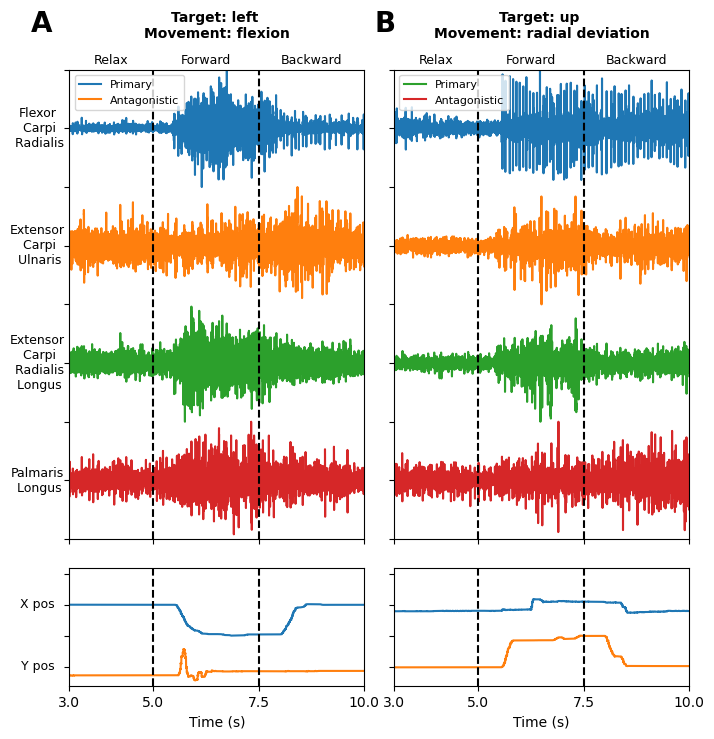

In [307]:
data3D_EMG = epochs_emg_pre.get_data() # Get all epochs data in a 3D matrix (trials x channels x samples
epochsKinematictmp = epochs_kin_pre.copy()

# dropped_indices = [n for n, dl in enumerate(epochsEMG.drop_log) if len(dl)] # Indices of rejected epochs
# epochsKinematictmp = epochsKinematictmp.drop(dropped_indices) # Drop corresponding kinematic epochs

data3D_Kinematic = epochsKinematictmp.get_data() #


time = np.zeros(shape=(data3D_EMG.shape[2]), dtype=np.float32)
targets = epochs_emg_pre.events[:,2]
muscle1 = muscle2 = muscle3 = muscle4 = np.zeros(shape=(data3D_EMG.shape[2]), dtype=np.float32)

movement = {1: "flexion", 2: "extension", 3: "radial deviation", 4: "ulnar deviation", 5: "D1", 6: "D2", 7: "D3", 8: "D4"}
target = {1: "left", 2: "right", 3: "up", 4: "down", 5: "D1", 6: "D2", 7: "D3", 8: "D4"}

for x in range(data3D_EMG.shape[2]):
    time[x] = x * 1/FS

#select a random flexion trial
movement_code = 1       # 1=Flexión
indices = np.where(targets == movement_code)[0]

selected_trial = np.random.choice(indices) #Trial to be plotted
#muscle data 
muscle1 = data3D_EMG[selected_trial,0,:] - data3D_EMG[selected_trial,1,:] #Extensor Carpi Radialis Longus, associated with the radial deviation movement
muscle2 = data3D_EMG[selected_trial,2,:] - data3D_EMG[selected_trial,3,:] #Extensor Carpi Ulnaris, associated with the extension movement
muscle3 = data3D_EMG[selected_trial,4,:] - data3D_EMG[selected_trial,5,:] #Flexor Carpi Radialis, associated with the flexion movement
muscle4 = data3D_EMG[selected_trial,6,:] - data3D_EMG[selected_trial,7,:] #Palmaris Longus, associated with the ulnar deviation movement
NormalizedMuscle1 = muscle1/np.max(np.abs(muscle1))
NormalizedMuscle2 = muscle2/np.max(np.abs(muscle2))
NormalizedMuscle3 = muscle3/np.max(np.abs(muscle3))
NormalizedMuscle4 = muscle4/np.max(np.abs(muscle4))
X = data3D_Kinematic[selected_trial,0,:]
Y = data3D_Kinematic[selected_trial,1,:]

#If variance is lower than a threshold, then normalize against the value reported in the literature
if np.var(X) < 1:
    NormalizedX = X / 90
else:
    NormalizedX = X/np.max(np.abs(X))
if np.var(Y) < 1:
    NormalizedY = Y / 45
else:
    NormalizedY = Y/np.max(np.abs(Y))

if 1:#target[targets[selected_trial]] == "up" or target[targets[selected_trial]] == "down":
    print("Trial %d (%s)" %(selected_trial,movement[targets[selected_trial]]))
    from matplotlib import gridspec
    
    fig,axs = plt.subplots(2,2, figsize=(8, 8), sharex='col', sharey='row', gridspec_kw={
                    'height_ratios': [4, 1],
                    'wspace': 0.1,
                    'hspace': 0.1})
    axs[0,0].set_title("Target: {} \nMovement: {}".format(target[targets[selected_trial]], movement[targets[selected_trial]]), fontsize=10, y=1.05, fontweight='bold')
    axs[0,0].plot(time[1536:], NormalizedMuscle3[1536:] + 6, label='Primary')
    axs[0,0].plot(time[1536:], NormalizedMuscle2[1536:] + 4, label='Antagonistic')
    axs[0,0].plot(time[1536:], NormalizedMuscle1[1536:] + 2)
    axs[0,0].plot(time[1536:], NormalizedMuscle4[1536:])
    axs[0,0].axvline(x = 5.0, color= 'black', linestyle = 'dashed')  
    axs[0,0].axvline(x = 7.5, color= 'black', linestyle = 'dashed')
    xticks = [3, 5, 7.5, 10]
    axs[0,0].set_xticks(xticks)
    axs[0,0].set_yticklabels([]) 
    axs[0,0].set_xlim(3,10)
    axs[0,0].set_ylim(-1.,7.)
    axs[0,0].legend(loc='upper left', fontsize=8)



    xmin = axs[0,0].get_xlim()[0] #(previous y location: 0, 2.5, 5, 7.5)
    axs[0,0].text(xmin-0.75, 0, 'Palmaris\n Longus', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)
    axs[0,0].text(xmin-0.75, 2, 'Extensor\n Carpi\n Radialis\n Longus', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)
    axs[0,0].text(xmin-0.75, 4, 'Extensor\n Carpi\n Ulnaris', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)
    axs[0,0].text(xmin-0.75, 6, 'Flexor\n Carpi\n Radialis', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)
    # add text just above the top axis
    ymax = axs[0,0].get_ylim()[1]
    axs[0,0].text(4, ymax+0.05, 'Relax', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
    axs[0,0].text(6.25, ymax+0.05, 'Forward', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
    axs[0,0].text(8.75, ymax+0.05, 'Backward', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
    axs[1,0].set_xlabel('Time (s)')
    axs[1,0].plot(time[1536:], NormalizedX[1536:] + 2)
    axs[1,0].plot(time[1536:], NormalizedY[1536:])
    axs[1,0].axvline(x = 5.0, color= 'black', linestyle = 'dashed')  
    axs[1,0].axvline(x = 7.5, color= 'black', linestyle = 'dashed')
    xticks = [3, 5, 7.5, 10]
    axs[1,0].set_xticks(xticks)
    axs[1,0].set_yticklabels([]) 
    # add text just left the left axis
    xmin = axs[1,0].get_xlim()[0]
    axs[1,0].text(xmin-0.75, 0, 'Y pos', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)
    axs[1,0].text(xmin-0.75, 2, 'X pos', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)

    # the other two grpahs

    #select a random radial deviation trial
    movement_code = 3       # 3=Radial Deviation
    indices = np.where(targets == movement_code)[0]

    selected_trial = np.random.choice(indices) #Trial to be plotted
    print("Trial %d (%s)" %(selected_trial,movement[targets[selected_trial]]))
    #muscle data 
    muscle1 = data3D_EMG[selected_trial,0,:] - data3D_EMG[selected_trial,1,:] #Extensor Carpi Radialis Longus, associated with the radial deviation movement
    muscle2 = data3D_EMG[selected_trial,2,:] - data3D_EMG[selected_trial,3,:] #Extensor Carpi Ulnaris, associated with the extension movement
    muscle3 = data3D_EMG[selected_trial,4,:] - data3D_EMG[selected_trial,5,:] #Flexor Carpi Radialis, associated with the flexion movement
    muscle4 = data3D_EMG[selected_trial,6,:] - data3D_EMG[selected_trial,7,:] #Palmaris Longus, associated with the ulnar deviation movement
    NormalizedMuscle1 = muscle1/np.max(np.abs(muscle1))
    NormalizedMuscle2 = muscle2/np.max(np.abs(muscle2))
    NormalizedMuscle3 = muscle3/np.max(np.abs(muscle3))
    NormalizedMuscle4 = muscle4/np.max(np.abs(muscle4))
    X = data3D_Kinematic[selected_trial,0,:]
    Y = data3D_Kinematic[selected_trial,1,:]
    #If variance is lower than a threshold, then normalize against the value reported in the literature
    if np.var(X) < 1:
        NormalizedX = X / 90
    else:
        NormalizedX = X/np.max(np.abs(X))
    if np.var(Y) < 1:
        NormalizedY = Y / 45
    else:
        NormalizedY = Y/np.max(np.abs(Y))

    axs[0,1].set_title("Target: {} \nMovement: {}".format(target[targets[selected_trial]], movement[targets[selected_trial]]), fontsize=10, y=1.05, fontweight='bold')
    axs[0,1].plot(time[1536:], NormalizedMuscle3[1536:] + 6)
    axs[0,1].plot(time[1536:], NormalizedMuscle2[1536:] + 4)
    axs[0,1].plot(time[1536:], NormalizedMuscle1[1536:] + 2, label='Primary')
    axs[0,1].plot(time[1536:], NormalizedMuscle4[1536:], label='Antagonistic')

    axs[0,1].axvline(x = 5.0, color= 'black', linestyle = 'dashed')  
    axs[0,1].axvline(x = 7.5, color= 'black', linestyle = 'dashed')
    xticks = [3, 5, 7.5, 10]
    axs[0,1].set_xticks(xticks)
    axs[0,1].set_yticklabels([])
    axs[0,1].set_xlim(3,10)
    axs[0,1].set_ylim(-1.,7.) 
    axs[0,1].legend(loc='upper left', fontsize=8)

    # add text just above the top axis
    ymax = axs[0,1].get_ylim()[1]
    axs[0,1].text(4, ymax+0.05, 'Relax', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
    axs[0,1].text(6.25, ymax+0.05, 'Forward', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
    axs[0,1].text(8.75, ymax+0.05, 'Backward', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
    axs[1,1].set_xlabel('Time (s)')
    axs[1,1].plot(time[1536:], NormalizedX[1536:] + 2)
    axs[1,1].plot(time[1536:], NormalizedY[1536:])
    axs[1,1].axvline(x = 5.0, color= 'black', linestyle = 'dashed')  
    axs[1,1].axvline(x = 7.5, color= 'black', linestyle = 'dashed')
    xticks = [3, 5, 7.5, 10]
    axs[1,1].set_xticks(xticks)
    axs[1,1].set_yticklabels([]) 

    fig.text(0.09, 0.92, 'A', ha='center', va='bottom', fontsize=20, rotation=0, color='k', zorder=11, fontweight='bold')
    fig.text(0.52, 0.92, 'B', ha='center', va='bottom', fontsize=20, rotation=0, color='k', zorder=11, fontweight='bold')
    

    fig.tight_layout()
    plt.show()

    output_path = os.path.join(output_dir, f"sub-{subject}_EMG.pdf")
    fig.savefig(output_path, dpi=600, bbox_inches='tight') # Save the figure

# 2) Encoder Data

Dropped 0 epochs: 


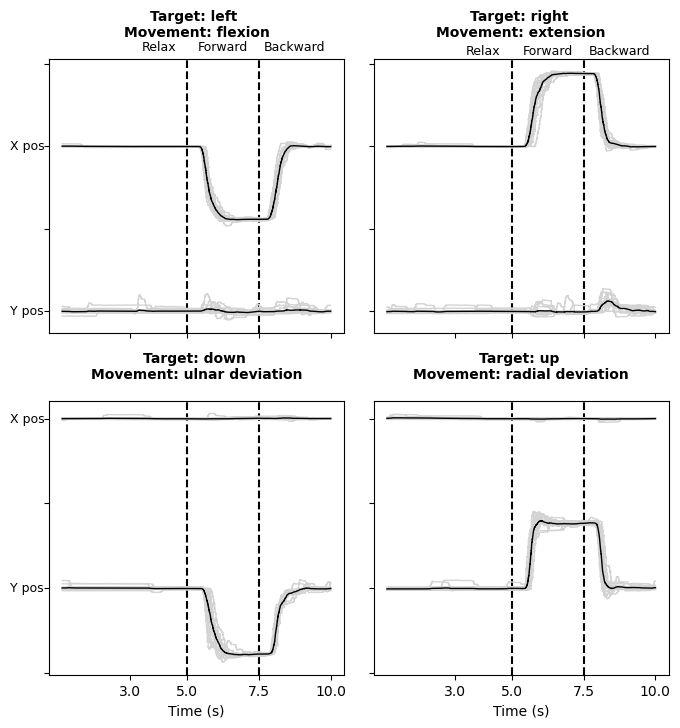

Text(0.5, 0, 'Time (s)')

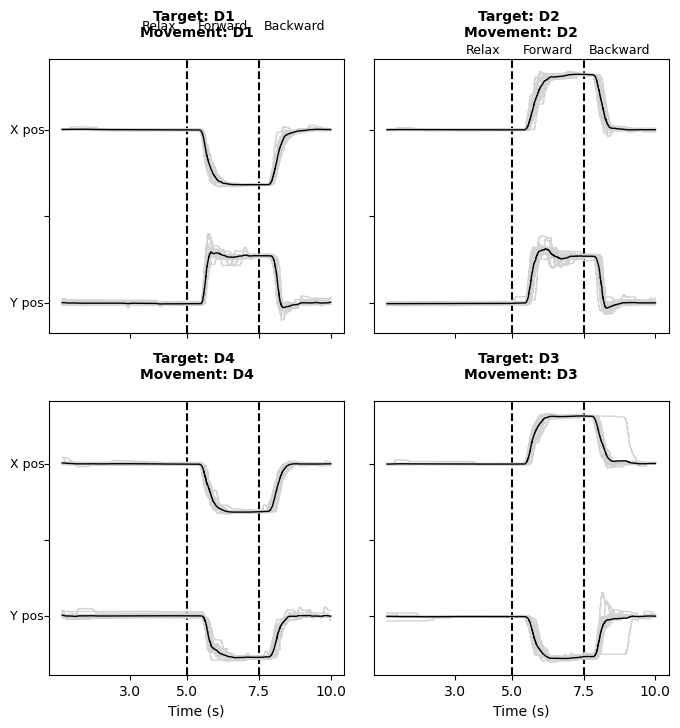

In [308]:
epochsKinematictmp = epochs_kin_pre.copy()

def custom_rejection_criteria(epoch_data):
    # Define custom rejection criteria
    max_amplitude = 100  # Example threshold in units of the data
    if (np.max(np.abs(epoch_data), axis=1) > max_amplitude).any():
        return True  # Reject epoch
    return False  # Keep epoch  

# Apply the custom function to each epoch to create a boolean mask
# This creates a list of booleans, where True means the epoch is "bad" according to the function
bad_epochs_mask = [custom_rejection_criteria(epoch) for epoch in epochsKinematictmp.get_data()]

# Drop the bad epochs using the mask
# The 'drop' method can take a boolean mask or indices
epochsKinematictmp.drop(bad_epochs_mask, reason='custom_criteria')

data3D_Kinematic = epochsKinematictmp.get_data() #

event_id= {"Flexion":1, "Extension":2, "Radial D.":3, "Ulnar D.":4}
data3D_Kinematic_Flexion = epochsKinematictmp['1'].get_data()
data3D_Kinematic_Extension = epochsKinematictmp['2'].get_data()
data3D_Kinematic_Radial = epochsKinematictmp['3'].get_data()
data3D_Kinematic_Ulnar = epochsKinematictmp['4'].get_data()

data3D_D1 = epochsKinematictmp['5'].get_data()
data3D_D2 = epochsKinematictmp['6'].get_data()
data3D_D3 = epochsKinematictmp['7'].get_data()
data3D_D4 = epochsKinematictmp['8'].get_data()

Normalized_Flexion = np.zeros(shape=(data3D_Kinematic_Flexion.shape[0], data3D_Kinematic_Flexion.shape[1], data3D_Kinematic_Flexion.shape[2]), dtype=np.float32)
Normalized_Extension = np.zeros(shape=(data3D_Kinematic_Extension.shape[0], data3D_Kinematic_Extension.shape[1], data3D_Kinematic_Extension.shape[2]), dtype=np.float32)
Normalized_Radial = np.zeros(shape=(data3D_Kinematic_Radial.shape[0], data3D_Kinematic_Radial.shape[1], data3D_Kinematic_Radial.shape[2]), dtype=np.float32)
Normalized_Ulnar = np.zeros(shape=(data3D_Kinematic_Ulnar.shape[0], data3D_Kinematic_Ulnar.shape[1], data3D_Kinematic_Ulnar.shape[2]), dtype=np.float32)

Normalized_D1 = np.zeros(shape=(data3D_D1.shape[0], data3D_D1.shape[1], data3D_D1.shape[2]), dtype=np.float32)
Normalized_D2 = np.zeros(shape=(data3D_D2.shape[0], data3D_D2.shape[1], data3D_D2.shape[2]), dtype=np.float32)
Normalized_D3 = np.zeros(shape=(data3D_D3.shape[0], data3D_D3.shape[1], data3D_D3.shape[2]), dtype=np.float32)
Normalized_D4 = np.zeros(shape=(data3D_D4.shape[0], data3D_D4.shape[1], data3D_D4.shape[2]), dtype=np.float32)

flex_count = extension_count = radial_count = ulnar_count = D1_count = D2_count = D3_count = D4_count = 0

targets = epochsKinematictmp.events[:,2]

time = np.zeros(shape=(data3D_Kinematic.shape[2]), dtype=np.float32)

for x in range(data3D_Kinematic.shape[2]):
    time[x] = x * 1/FS



for selected_trial in range(0,epochsKinematictmp.get_data().shape[0]):
    #encoders data
    X = data3D_Kinematic[selected_trial,0,:]
    Y = data3D_Kinematic[selected_trial,1,:]
    NormalizedY = Y / 90
    NormalizedX = X / 90
    
    if targets[selected_trial] == 1:        
        Normalized_Flexion[flex_count,0,:] = NormalizedX
        Normalized_Flexion[flex_count,1,:] = NormalizedY
        flex_count += 1
    elif targets[selected_trial] == 2:
        Normalized_Extension[extension_count,0,:] = NormalizedX
        Normalized_Extension[extension_count,1,:] = NormalizedY
        extension_count += 1
    elif targets[selected_trial] == 3:
        Normalized_Radial[radial_count,0,:] = NormalizedX
        Normalized_Radial[radial_count,1,:] = NormalizedY
        radial_count += 1
    elif targets[selected_trial] == 4:
        Normalized_Ulnar[ulnar_count,0,:] = NormalizedX
        Normalized_Ulnar[ulnar_count,1,:] = NormalizedY
        ulnar_count += 1
    elif targets[selected_trial] == 5:
        Normalized_D1[D1_count,0,:] = NormalizedX
        Normalized_D1[D1_count,1,:] = NormalizedY
        D1_count += 1
    elif targets[selected_trial] == 6:
        Normalized_D2[D2_count,0,:] = NormalizedX
        Normalized_D2[D2_count,1,:] = NormalizedY
        D2_count += 1
    elif targets[selected_trial] == 7:
        Normalized_D3[D3_count,0,:] = NormalizedX
        Normalized_D3[D3_count,1,:] = NormalizedY
        D3_count += 1
    elif targets[selected_trial] == 8:
        Normalized_D4[D4_count,0,:] = NormalizedX
        Normalized_D4[D4_count,1,:] = NormalizedY
        D4_count += 1
    
from matplotlib import gridspec

fig,axs = plt.subplots(2,2, figsize=(8, 8), sharex='col', sharey='row', gridspec_kw={
                'height_ratios': [1, 1],
                'wspace': 0.1,
                'hspace': 0.25})

#Flexion plots
axs[0,0].set_title("Target: left \nMovement: flexion", fontsize=10, y=1.05, fontweight='bold')

axs[0,0].axvline(x = 5.0, color= 'black', linestyle = 'dashed')  
axs[0,0].axvline(x = 7.5, color= 'black', linestyle = 'dashed')
xticks = [3, 5, 7.5, 10]
yticks = [0, 1, 2, 3]
axs[0,0].set_xticks(xticks)
axs[0,0].set_yticks(yticks)
axs[0,0].set_yticklabels([]) 

#plot data
for i in range(Normalized_Flexion.shape[0]):
    axs[0,0].plot(time[1536:], Normalized_Flexion[i,0,1536:] + 2, color='lightgray', linewidth=1)
    axs[0,0].plot(time[1536:], Normalized_Flexion[i,1,1536:], color='lightgray', linewidth=1)

axs[0,0].plot(time[1536:], np.mean(Normalized_Flexion[:,0,1536:], axis=0) + 2, color='black', linewidth=1)
axs[0,0].plot(time[1536:], np.mean(Normalized_Flexion[:,1,1536:], axis=0), color='black', linewidth=1)

 
# add text just left the left axis
xmin = axs[1,0].get_xlim()[0]
axs[0,0].text(xmin-0.75, 0, 'Y pos', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)
axs[0,0].text(xmin-0.75, 2, 'X pos', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)

# add text just above the top axis
ymax = axs[0,0].get_ylim()[1]
axs[0,0].text(4, ymax+0.96, 'Relax', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
axs[0,0].text(6.25, ymax+0.96, 'Forward', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
axs[0,0].text(8.75, ymax+0.96, 'Backward', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)

#Extension plots
axs[0,1].set_title("Target: right \nMovement: extension", fontsize=10, y=1.05, fontweight='bold')

axs[0,1].axvline(x = 5.0, color= 'black', linestyle = 'dashed')  
axs[0,1].axvline(x = 7.5, color= 'black', linestyle = 'dashed')
xticks = [3, 5, 7.5, 10]
yticks = [0, 1, 2, 3]
axs[0,1].set_xticks(xticks)
axs[0,1].set_yticks(yticks)
axs[0,1].set_yticklabels([]) 

#plot data
for i in range(Normalized_Extension.shape[0]):
    axs[0,1].plot(time[1536:], Normalized_Extension[i,0,1536:] + 2, color='lightgray', linewidth=1)
    axs[0,1].plot(time[1536:], Normalized_Extension[i,1,1536:], color='lightgray', linewidth=1)

axs[0,1].plot(time[1536:], np.mean(Normalized_Extension[:,0,1536:], axis=0) + 2, color='black', linewidth=1)
axs[0,1].plot(time[1536:], np.mean(Normalized_Extension[:,1,1536:], axis=0), color='black', linewidth=1)

# add text just above the top axis
ymax = axs[0,1].get_ylim()[1]
axs[0,1].text(4, ymax+0.02, 'Relax', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
axs[0,1].text(6.25, ymax+0.02, 'Forward', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
axs[0,1].text(8.75, ymax+0.02, 'Backward', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)

#Radial Deviation plots
axs[1,1].set_title("Target: up \nMovement: radial deviation", fontsize=10, y=1.05, fontweight='bold')

axs[1,1].axvline(x = 5.0, color= 'black', linestyle = 'dashed')  
axs[1,1].axvline(x = 7.5, color= 'black', linestyle = 'dashed')
xticks = [3, 5, 7.5, 10]
yticks = [0, 2]
axs[1,1].set_xticks(xticks)
axs[1,1].set_yticks(yticks)
axs[1,1].set_yticklabels([]) 

#plot data
for i in range(Normalized_Radial.shape[0]):
    axs[1,1].plot(time[1536:], Normalized_Radial[i,0,1536:] + 2, color='lightgray', linewidth=1)
    axs[1,1].plot(time[1536:], Normalized_Radial[i,1,1536:], color='lightgray', linewidth=1)

axs[1,1].plot(time[1536:], np.mean(Normalized_Radial[:,0,1536:], axis=0) + 2, color='black', linewidth=1)
axs[1,1].plot(time[1536:], np.mean(Normalized_Radial[:,1,1536:], axis=0), color='black', linewidth=1)

axs[1,1].set_xlabel('Time (s)')

#Ulnar deviation plots
axs[1,0].set_title("Target: down \nMovement: ulnar deviation", fontsize=10, y=1.05, fontweight='bold')

axs[1,0].axvline(x = 5.0, color= 'black', linestyle = 'dashed')  
axs[1,0].axvline(x = 7.5, color= 'black', linestyle = 'dashed')
xticks = [3, 5, 7.5, 10]
yticks = [-1, 0, 1, 2]
axs[1,0].set_xticks(xticks)
axs[1,0].set_yticks(yticks)
axs[1,0].set_yticklabels([]) 

#plot data
for i in range(Normalized_Ulnar.shape[0]):
    axs[1,0].plot(time[1536:], Normalized_Ulnar[i,0,1536:] + 2, color='lightgray', linewidth=1)
    axs[1,0].plot(time[1536:], Normalized_Ulnar[i,1,1536:], color='lightgray', linewidth=1)

axs[1,0].plot(time[1536:], np.mean(Normalized_Ulnar[:,0,1536:], axis=0) + 2, color='black', linewidth=1)
axs[1,0].plot(time[1536:], np.mean(Normalized_Ulnar[:,1,1536:], axis=0), color='black', linewidth=1)

 
# add text just left the left axis
xmin = axs[1,0].get_xlim()[0]
axs[1,0].text(xmin-0.75, 0, 'Y pos', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)
axs[1,0].text(xmin-0.75, 2, 'X pos', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)

axs[1,0].set_xlabel('Time (s)')

plt.show()
output_path = os.path.join(output_dir, f"sub-{subject}_Encoders.pdf")
fig.savefig(output_path, dpi=600, bbox_inches='tight') # Save the figure

fig2,axs2 = plt.subplots(2,2, figsize=(8, 8), sharex='col', sharey='row', gridspec_kw={
                'height_ratios': [1, 1],
                'wspace': 0.1,
                'hspace': 0.25})

#D1 plots
axs2[0,0].set_title("Target: D1 \nMovement: D1", fontsize=10, y=1.05, fontweight='bold')

axs2[0,0].axvline(x = 5.0, color= 'black', linestyle = 'dashed')  
axs2[0,0].axvline(x = 7.5, color= 'black', linestyle = 'dashed')
xticks = [3, 5, 7.5, 10]
yticks = [0, 1, 2, 3]
axs2[0,0].set_xticks(xticks)
axs2[0,0].set_yticks(yticks)
axs2[0,0].set_yticklabels([]) 

#plot data
for i in range(Normalized_D1.shape[0]):
    axs2[0,0].plot(time[1536:], Normalized_D1[i,0,1536:] + 2, color='lightgray', linewidth=1)
    axs2[0,0].plot(time[1536:], Normalized_D1[i,1,1536:], color='lightgray', linewidth=1)

axs2[0,0].plot(time[1536:], np.mean(Normalized_D1[:,0,1536:], axis=0) + 2, color='black', linewidth=1)
axs2[0,0].plot(time[1536:], np.mean(Normalized_D1[:,1,1536:], axis=0), color='black', linewidth=1)

 
# add text just left the left axis
xmin = axs2[0,0].get_xlim()[0]
axs2[0,0].text(xmin-0.75, 0, 'Y pos', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)
axs2[0,0].text(xmin-0.75, 2, 'X pos', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)

# add text just above the top axis
ymax = axs2[0,0].get_ylim()[1]
axs2[0,0].text(4, ymax+0.96, 'Relax', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
axs2[0,0].text(6.25, ymax+0.96, 'Forward', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
axs2[0,0].text(8.75, ymax+0.96, 'Backward', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)

#D2 plots
axs2[0,1].set_title("Target: D2 \nMovement: D2", fontsize=10, y=1.05, fontweight='bold')

axs2[0,1].axvline(x = 5.0, color= 'black', linestyle = 'dashed')  
axs2[0,1].axvline(x = 7.5, color= 'black', linestyle = 'dashed')
xticks = [3, 5, 7.5, 10]
yticks = [0, 1, 2, 3]
axs2[0,1].set_xticks(xticks)
axs2[0,1].set_yticks(yticks)
axs2[0,1].set_yticklabels([]) 

#plot data
for i in range(Normalized_D2.shape[0]):
    axs2[0,1].plot(time[1536:], Normalized_D2[i,0,1536:] + 2, color='lightgray', linewidth=1)
    axs2[0,1].plot(time[1536:], Normalized_D2[i,1,1536:], color='lightgray', linewidth=1)

axs2[0,1].plot(time[1536:], np.mean(Normalized_D2[:,0,1536:], axis=0) + 2, color='black', linewidth=1)
axs2[0,1].plot(time[1536:], np.mean(Normalized_D2[:,1,1536:], axis=0), color='black', linewidth=1)

# add text just above the top axis
ymax = axs2[0,1].get_ylim()[1]
axs2[0,1].text(4, ymax+0.02, 'Relax', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
axs2[0,1].text(6.25, ymax+0.02, 'Forward', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
axs2[0,1].text(8.75, ymax+0.02, 'Backward', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)

#D3 plots
axs2[1,1].set_title("Target: D3 \nMovement: D3", fontsize=10, y=1.05, fontweight='bold')

axs2[1,1].axvline(x = 5.0, color= 'black', linestyle = 'dashed')  
axs2[1,1].axvline(x = 7.5, color= 'black', linestyle = 'dashed')
xticks = [3, 5, 7.5, 10]
yticks = [0, 2]
axs2[1,1].set_xticks(xticks)
axs2[1,1].set_yticks(yticks)
axs2[1,1].set_yticklabels([]) 

#plot data
for i in range(Normalized_D3.shape[0]):
    axs2[1,1].plot(time[1536:], Normalized_D3[i,0,1536:] + 2, color='lightgray', linewidth=1)
    axs2[1,1].plot(time[1536:], Normalized_D3[i,1,1536:], color='lightgray', linewidth=1)

axs2[1,1].plot(time[1536:], np.mean(Normalized_D3[:,0,1536:], axis=0) + 2, color='black', linewidth=1)
axs2[1,1].plot(time[1536:], np.mean(Normalized_D3[:,1,1536:], axis=0), color='black', linewidth=1)

axs2[1,1].set_xlabel('Time (s)')

#D4plots
axs2[1,0].set_title("Target: D4 \nMovement: D4", fontsize=10, y=1.05, fontweight='bold')

axs2[1,0].axvline(x = 5.0, color= 'black', linestyle = 'dashed')  
axs2[1,0].axvline(x = 7.5, color= 'black', linestyle = 'dashed')
xticks = [3, 5, 7.5, 10]
yticks = [-1, 0, 1, 2]
axs2[1,0].set_xticks(xticks)
axs2[1,0].set_yticks(yticks)
axs2[1,0].set_yticklabels([]) 

#plot data
for i in range(Normalized_D4.shape[0]):
    axs2[1,0].plot(time[1536:], Normalized_D4[i,0,1536:] + 2, color='lightgray', linewidth=1)
    axs2[1,0].plot(time[1536:], Normalized_D4[i,1,1536:], color='lightgray', linewidth=1)

axs2[1,0].plot(time[1536:], np.mean(Normalized_D4[:,0,1536:], axis=0) + 2, color='black', linewidth=1)
axs2[1,0].plot(time[1536:], np.mean(Normalized_D4[:,1,1536:], axis=0), color='black', linewidth=1)

 
# add text just left the left axis
xmin = axs2[1,0].get_xlim()[0]
axs2[1,0].text(xmin-0.75, 0, 'Y pos', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)
axs2[1,0].text(xmin-0.75, 2, 'X pos', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)

axs2[1,0].set_xlabel('Time (s)')

# 3) Kinematic metrics

Dropped 0 epochs: 


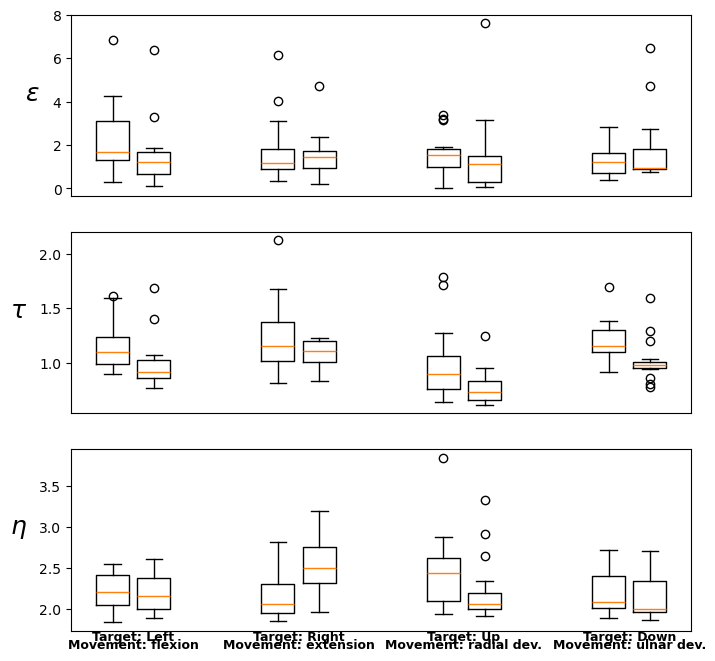

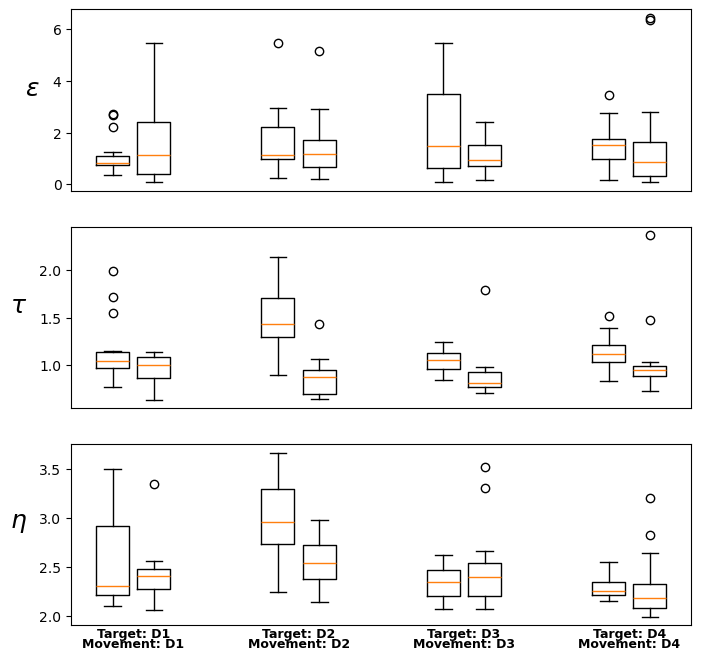

In [309]:
# def custom_rejection_criteria(epoch_data):
#     # Define custom rejection criteria
#     max_amplitude = 100  # Example threshold in units of the data
#     if (np.max(np.abs(epoch_data), axis=1) > max_amplitude).any():
#         return True  # Reject epoch
#     return False  # Keep epoch  

# # Apply the custom function to each epoch to create a boolean mask
# # This creates a list of booleans, where True means the epoch is "bad" according to the function
# bad_epochs_mask = [custom_rejection_criteria(epoch) for epoch in epochsKinematictmp.get_data()]

# # Drop the bad epochs using the mask
# # The 'drop' method can take a boolean mask or indices
# epochsKinematictmp.drop(bad_epochs_mask, reason='custom_criteria')

# data3D_Kinematic = epochsKinematictmp.get_data()

data3D_EMG = epochs_emg_pre.get_data() # Get all epochs data in a 3D matrix (trials x channels x samples
epochsKinematictmp = epochs_kin_pre.copy()

dropped_indices = [n for n, dl in enumerate(epochs_emg_pre.drop_log) if len(dl)] # Indices of rejected epochs
epochsKinematictmp = epochsKinematictmp.drop(dropped_indices) # Drop corresponding kinematic epochs

data3D_Kinematic = epochsKinematictmp.get_data()

time = np.zeros(shape=(data3D_Kinematic.shape[2]), dtype=np.float32)
movement = {1: "Flexion", 2: "Extension", 3: "Radial D.", 4: "Ulnar D.", 5: "D1", 6: "D2", 7: "D3", 8: "D4"}

for x in range(data3D_Kinematic.shape[2]):
    time[x] = x * 1/FS

MotorPerformanceIndices = np.zeros(shape=(data3D_Kinematic.shape[0],6), dtype=np.float32)

for selected_trial in range(0,data3D_Kinematic.shape[0]-1):    
    #Computing motor performance indices
    X = data3D_Kinematic[selected_trial,0,:]
    Y = data3D_Kinematic[selected_trial,1,:]

    MotorPerformanceIndices[selected_trial, 0] = ComputeAccuracy(movement= movement[targets[selected_trial]], RawData= np.array([X,Y]), movementDirection= "FORWARD")
    MotorPerformanceIndices[selected_trial, 1] = ComputeAccuracy(movement= movement[targets[selected_trial]], RawData= np.array([X,Y]), movementDirection= "BACKWARD")

    MotorPerformanceIndices[selected_trial, 2] = ComputeExcecutionTime(movement= movement[targets[selected_trial]], RawData= np.array([X,Y]), movementDirection= "FORWARD")
    MotorPerformanceIndices[selected_trial, 3] = ComputeExcecutionTime(movement= movement[targets[selected_trial]], RawData= np.array([X,Y]), movementDirection= "BACKWARD")

    MotorPerformanceIndices[selected_trial, 4] = ComputeTrayectoryEfficiency(movement= movement[targets[selected_trial]], RawData= np.array([X,Y]), movementDirection= "FORWARD")
    MotorPerformanceIndices[selected_trial, 5] = ComputeTrayectoryEfficiency(movement= movement[targets[selected_trial]], RawData= np.array([X,Y]), movementDirection= "BACKWARD")

# Define nombres de columnas (siguiendo el orden de tus métricas)
columns = [
    'Accuracy_ForwardMovement', 'Accuracy_BackwardMovement',
    'ExecutionTime_ForwardMovement', 'ExecutionTime_BackwardMovement',
    'TrajectoryEfficiency_ForwardMovement', 'TrajectoryEfficiency_BackwardMovement'
]

# Crea un DataFrame a partir del array de métricas
df = pd.DataFrame(MotorPerformanceIndices, columns=columns)

# Añade columna de índice de trial (opcional)
df.insert(0, 'trial', df.index)

# Guarda como .tsv
output_path = os.path.join(output_dir, f"sub-{subject}_MotorPerformanceMetrics.tsv")
df.to_csv(output_path, sep='\t', index=False)

####Motor Performance Indices Box Plots

event_id= {"Flexion":1, "Extension":2, "Radial D.":3, "Ulnar D.":4, "D1":5, "D2":6, "D3":7, "D4":8}

data3D_Kinematic_Flexion = epochs_kin_pre['1'].get_data()
data3D_Kinematic_Extension = epochs_kin_pre['2'].get_data()
data3D_Kinematic_Radial = epochs_kin_pre['3'].get_data()
data3D_Kinematic_Ulnar = epochs_kin_pre['4'].get_data()
data3D_D1 = epochs_kin_pre['5'].get_data()
data3D_D2 = epochs_kin_pre['6'].get_data()
data3D_D3 = epochs_kin_pre['7'].get_data()
data3D_D4 = epochs_kin_pre['8'].get_data()

MotorPerformanceIndicesFlexion = np.zeros(shape=(data3D_Kinematic_Flexion.shape[0],8), dtype=np.float32)
MotorPerformanceIndicesExtension = np.zeros(shape=(data3D_Kinematic_Extension.shape[0],8), dtype=np.float32)
MotorPerformanceIndicesRadialD = np.zeros(shape=(data3D_Kinematic_Radial.shape[0],8), dtype=np.float32)
MotorPerformanceIndicesUlnarD = np.zeros(shape=(data3D_Kinematic_Ulnar.shape[0],8), dtype=np.float32)
MotorPerformanceIndicesD1 = np.zeros(shape=(data3D_D1.shape[0],8), dtype=np.float32)
MotorPerformanceIndicesD2 = np.zeros(shape=(data3D_D2.shape[0],8), dtype=np.float32)
MotorPerformanceIndicesD3 = np.zeros(shape=(data3D_D3.shape[0],8), dtype=np.float32)
MotorPerformanceIndicesD4 = np.zeros(shape=(data3D_D4.shape[0],8), dtype=np.float32)

#Compute Motor Performance Indices for each movement type
for selected_trial in range(0,data3D_Kinematic_Flexion.shape[0]):    
    #Computing motor performance indices
    X_Flexion = data3D_Kinematic_Flexion[selected_trial,0,:]
    Y_Flexion = data3D_Kinematic_Flexion[selected_trial,1,:]
    X_Extension = data3D_Kinematic_Extension[selected_trial,0,:]
    Y_Extension = data3D_Kinematic_Extension[selected_trial,1,:]
    X_RadialD = data3D_Kinematic_Radial[selected_trial,0,:]
    Y_RadialD = data3D_Kinematic_Radial[selected_trial,1,:]
    X_UlnarD = data3D_Kinematic_Ulnar[selected_trial,0,:]
    Y_UlnarD = data3D_Kinematic_Ulnar[selected_trial,1,:]
    X_D1 = data3D_D1[selected_trial,0,:]
    Y_D1 = data3D_D1[selected_trial,1,:]
    X_D2 = data3D_D2[selected_trial,0,:]
    Y_D2 = data3D_D2[selected_trial,1,:]
    X_D3 = data3D_D3[selected_trial,0,:]
    Y_D3 = data3D_D3[selected_trial,1,:]
    X_D4 = data3D_D4[selected_trial,0,:]
    Y_D4 = data3D_D4[selected_trial,1,:]


    MotorPerformanceIndicesFlexion[selected_trial, 0] = ComputeAccuracy(movement= "Flexion", RawData= np.array([X_Flexion,Y_Flexion]), movementDirection= "FORWARD")
    MotorPerformanceIndicesFlexion[selected_trial, 1] = ComputeAccuracy(movement= "Flexion", RawData= np.array([X_Flexion,Y_Flexion]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesFlexion[selected_trial, 2] = ComputeExcecutionTime(movement= "Flexion", RawData= np.array([X_Flexion,Y_Flexion]), movementDirection= "FORWARD")
    MotorPerformanceIndicesFlexion[selected_trial, 3] = ComputeExcecutionTime(movement= "Flexion", RawData= np.array([X_Flexion,Y_Flexion]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesFlexion[selected_trial, 4] = ComputeTrayectoryEfficiency(movement= "Flexion", RawData= np.array([X_Flexion,Y_Flexion]), movementDirection= "FORWARD")
    MotorPerformanceIndicesFlexion[selected_trial, 5] = ComputeTrayectoryEfficiency(movement= "Flexion", RawData= np.array([X_Flexion,Y_Flexion]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesFlexion[selected_trial, 6] = CheckStarAndEndPoints(movement= "Flexion", RawData= np.array([X_Flexion,Y_Flexion]), movementDirection= "FORWARD")
    MotorPerformanceIndicesFlexion[selected_trial, 7] = CheckStarAndEndPoints(movement= "Flexion", RawData= np.array([X_Flexion,Y_Flexion]), movementDirection= "BACKWARD")

    MotorPerformanceIndicesExtension[selected_trial, 0] = ComputeAccuracy(movement= "Extension", RawData= np.array([X_Extension,Y_Extension]), movementDirection= "FORWARD")
    MotorPerformanceIndicesExtension[selected_trial, 1] = ComputeAccuracy(movement= "Extension", RawData= np.array([X_Extension,Y_Extension]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesExtension[selected_trial, 2] = ComputeExcecutionTime(movement= "Extension", RawData= np.array([X_Extension,Y_Extension]), movementDirection= "FORWARD")
    MotorPerformanceIndicesExtension[selected_trial, 3] = ComputeExcecutionTime(movement= "Extension", RawData= np.array([X_Extension,Y_Extension]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesExtension[selected_trial, 4] = ComputeTrayectoryEfficiency(movement= "Extension", RawData= np.array([X_Extension,Y_Extension]), movementDirection= "FORWARD")
    MotorPerformanceIndicesExtension[selected_trial, 5] = ComputeTrayectoryEfficiency(movement= "Extension", RawData= np.array([X_Extension,Y_Extension]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesExtension[selected_trial, 6] = CheckStarAndEndPoints(movement= "Extension", RawData= np.array([X_Extension,Y_Extension]), movementDirection= "FORWARD")
    MotorPerformanceIndicesExtension[selected_trial, 7] = CheckStarAndEndPoints(movement= "Extension", RawData= np.array([X_Extension,Y_Extension]), movementDirection= "BACKWARD")

    MotorPerformanceIndicesRadialD[selected_trial, 0] = ComputeAccuracy(movement= "Radial D.", RawData= np.array([X_RadialD,Y_RadialD]), movementDirection= "FORWARD")
    MotorPerformanceIndicesRadialD[selected_trial, 1] = ComputeAccuracy(movement= "Radial D.", RawData= np.array([X_RadialD,Y_RadialD]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesRadialD[selected_trial, 2] = ComputeExcecutionTime(movement= "Radial D.", RawData= np.array([X_RadialD,Y_RadialD]), movementDirection= "FORWARD")
    MotorPerformanceIndicesRadialD[selected_trial, 3] = ComputeExcecutionTime(movement= "Radial D.", RawData= np.array([X_RadialD,Y_RadialD]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesRadialD[selected_trial, 4] = ComputeTrayectoryEfficiency(movement= "Radial D.", RawData= np.array([X_RadialD,Y_RadialD]), movementDirection= "FORWARD")
    MotorPerformanceIndicesRadialD[selected_trial, 5] = ComputeTrayectoryEfficiency(movement= "Radial D.", RawData= np.array([X_RadialD,Y_RadialD]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesRadialD[selected_trial, 6] = CheckStarAndEndPoints(movement= "Radial D.", RawData= np.array([X_RadialD,Y_RadialD]), movementDirection= "FORWARD")
    MotorPerformanceIndicesRadialD[selected_trial, 7] = CheckStarAndEndPoints(movement= "Radial D.", RawData= np.array([X_RadialD,Y_RadialD]), movementDirection= "BACKWARD")

    MotorPerformanceIndicesUlnarD[selected_trial, 0] = ComputeAccuracy(movement= "Ulnar D.", RawData= np.array([X_UlnarD,Y_UlnarD]), movementDirection= "FORWARD")
    MotorPerformanceIndicesUlnarD[selected_trial, 1] = ComputeAccuracy(movement= "Ulnar D.", RawData= np.array([X_UlnarD,Y_UlnarD]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesUlnarD[selected_trial, 2] = ComputeExcecutionTime(movement= "Ulnar D.", RawData= np.array([X_UlnarD,Y_UlnarD]), movementDirection= "FORWARD")
    MotorPerformanceIndicesUlnarD[selected_trial, 3] = ComputeExcecutionTime(movement= "Ulnar D.", RawData= np.array([X_UlnarD,Y_UlnarD]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesUlnarD[selected_trial, 4] = ComputeTrayectoryEfficiency(movement= "Ulnar D.", RawData= np.array([X_UlnarD,Y_UlnarD]), movementDirection= "FORWARD")
    MotorPerformanceIndicesUlnarD[selected_trial, 5] = ComputeTrayectoryEfficiency(movement= "Ulnar D.", RawData= np.array([X_UlnarD,Y_UlnarD]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesUlnarD[selected_trial, 6] = CheckStarAndEndPoints(movement= "Ulnar D.", RawData= np.array([X_UlnarD,Y_UlnarD]), movementDirection= "FORWARD")
    MotorPerformanceIndicesUlnarD[selected_trial, 7] = CheckStarAndEndPoints(movement= "Ulnar D.", RawData= np.array([X_UlnarD,Y_UlnarD]), movementDirection= "BACKWARD")

    MotorPerformanceIndicesD1[selected_trial, 0] = ComputeAccuracy(movement= "D1", RawData= np.array([X_D1,Y_D1]), movementDirection= "FORWARD")
    MotorPerformanceIndicesD1[selected_trial, 1] = ComputeAccuracy(movement= "D1", RawData= np.array([X_D1,Y_D1]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesD1[selected_trial, 2] = ComputeExcecutionTime(movement= "D1", RawData= np.array([X_D1,Y_D1]), movementDirection= "FORWARD")
    MotorPerformanceIndicesD1[selected_trial, 3] = ComputeExcecutionTime(movement= "D1", RawData= np.array([X_D1,Y_D1]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesD1[selected_trial, 4] = ComputeTrayectoryEfficiency(movement= "D1", RawData= np.array([X_D1,Y_D1]), movementDirection= "FORWARD")
    MotorPerformanceIndicesD1[selected_trial, 5] = ComputeTrayectoryEfficiency(movement= "D1", RawData= np.array([X_D1,Y_D1]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesD1[selected_trial, 6] = CheckStarAndEndPoints(movement= "D1", RawData= np.array([X_D1,Y_D1]), movementDirection= "FORWARD")
    MotorPerformanceIndicesD1[selected_trial, 7] = CheckStarAndEndPoints(movement= "D1", RawData= np.array([X_D1,Y_D1]), movementDirection= "BACKWARD")

    MotorPerformanceIndicesD2[selected_trial, 0] = ComputeAccuracy(movement= "D2", RawData= np.array([X_D2,Y_D2]), movementDirection= "FORWARD")
    MotorPerformanceIndicesD2[selected_trial, 1] = ComputeAccuracy(movement= "D2", RawData= np.array([X_D2,Y_D2]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesD2[selected_trial, 2] = ComputeExcecutionTime(movement= "D2", RawData= np.array([X_D2,Y_D2]), movementDirection= "FORWARD")
    MotorPerformanceIndicesD2[selected_trial, 3] = ComputeExcecutionTime(movement= "D2", RawData= np.array([X_D2,Y_D2]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesD2[selected_trial, 4] = ComputeTrayectoryEfficiency(movement= "D2", RawData= np.array([X_D2,Y_D2]), movementDirection= "FORWARD")
    MotorPerformanceIndicesD2[selected_trial, 5] = ComputeTrayectoryEfficiency(movement= "D2", RawData= np.array([X_D2,Y_D2]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesD2[selected_trial, 6] = CheckStarAndEndPoints(movement= "D2", RawData= np.array([X_D2,Y_D2]), movementDirection= "FORWARD")
    MotorPerformanceIndicesD2[selected_trial, 7] = CheckStarAndEndPoints(movement= "D2", RawData= np.array([X_D2,Y_D2]), movementDirection= "BACKWARD")

    MotorPerformanceIndicesD3[selected_trial, 0] = ComputeAccuracy(movement= "D3", RawData= np.array([X_D3,Y_D3]), movementDirection= "FORWARD")
    MotorPerformanceIndicesD3[selected_trial, 1] = ComputeAccuracy(movement= "D3", RawData= np.array([X_D3,Y_D3]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesD3[selected_trial, 2] = ComputeExcecutionTime(movement= "D3", RawData= np.array([X_D3,Y_D3]), movementDirection= "FORWARD")
    MotorPerformanceIndicesD3[selected_trial, 3] = ComputeExcecutionTime(movement= "D3", RawData= np.array([X_D3,Y_D3]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesD3[selected_trial, 4] = ComputeTrayectoryEfficiency(movement= "D3", RawData= np.array([X_D3,Y_D3]), movementDirection= "FORWARD")
    MotorPerformanceIndicesD3[selected_trial, 5] = ComputeTrayectoryEfficiency(movement= "D3", RawData=np.array([X_D3,Y_D3]), movementDirection="BACKWARD")
    MotorPerformanceIndicesD3[selected_trial, 6] = CheckStarAndEndPoints(movement= "D3", RawData= np.array([X_D3,Y_D3]), movementDirection= "FORWARD")
    MotorPerformanceIndicesD3[selected_trial, 7] = CheckStarAndEndPoints(movement= "D3", RawData= np.array([X_D3,Y_D3]), movementDirection= "BACKWARD")


    MotorPerformanceIndicesD4[selected_trial, 0] = ComputeAccuracy(movement= "D4", RawData= np.array([X_D4,Y_D4]), movementDirection= "FORWARD")
    MotorPerformanceIndicesD4[selected_trial, 1] = ComputeAccuracy(movement= "D4", RawData= np.array([X_D4,Y_D4]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesD4[selected_trial, 2] = ComputeExcecutionTime(movement= "D4", RawData= np.array([X_D4,Y_D4]), movementDirection= "FORWARD")
    MotorPerformanceIndicesD4[selected_trial, 3] = ComputeExcecutionTime(movement= "D4", RawData= np.array([X_D4,Y_D4]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesD4[selected_trial, 4] = ComputeTrayectoryEfficiency(movement= "D4", RawData= np.array([X_D4,Y_D4]), movementDirection= "FORWARD")
    MotorPerformanceIndicesD4[selected_trial, 5] = ComputeTrayectoryEfficiency(movement= "D4", RawData= np.array([X_D4,Y_D4]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesD4[selected_trial, 6] = CheckStarAndEndPoints(movement= "D4", RawData= np.array([X_D4,Y_D4]), movementDirection= "FORWARD")
    MotorPerformanceIndicesD4[selected_trial, 7] = CheckStarAndEndPoints(movement= "D4", RawData= np.array([X_D4,Y_D4]), movementDirection= "BACKWARD")

# Función auxiliar para filtrar métricas basadas en la comprobación de inicio/fin y eliminar NaNs
def filter_valid_trials(matrix, metric_col, check_col):
    # Asume que la función de comprobación devuelve 1 (o valor > 0) si es válido
    valid_mask = matrix[:, check_col] > 0 
    data = matrix[valid_mask, metric_col]
    return data[~np.isnan(data)]

# Create a figure and an axes object
fig, axs = plt.subplots(3,1, figsize=(8, 8), sharex=True)

# Plot the box plot
axs[0].set_ylabel(r'$\varepsilon$', rotation='horizontal', fontsize=18, labelpad=15)
# Accuracy = [MotorPerformanceIndicesFlexion[:, 0], MotorPerformanceIndicesFlexion[:, 1], MotorPerformanceIndicesExtension[:, 0], MotorPerformanceIndicesExtension[:, 1],MotorPerformanceIndicesRadialD[:, 0], MotorPerformanceIndicesRadialD[:, 1],MotorPerformanceIndicesUlnarD[:, 0], MotorPerformanceIndicesUlnarD[:, 1]]
Accuracy = [
    filter_valid_trials(MotorPerformanceIndicesFlexion, 0, 6), filter_valid_trials(MotorPerformanceIndicesFlexion, 1, 7),
    filter_valid_trials(MotorPerformanceIndicesExtension, 0, 6), filter_valid_trials(MotorPerformanceIndicesExtension, 1, 7),
    filter_valid_trials(MotorPerformanceIndicesRadialD, 0, 6), filter_valid_trials(MotorPerformanceIndicesRadialD, 1, 7),
    filter_valid_trials(MotorPerformanceIndicesUlnarD, 0, 6), filter_valid_trials(MotorPerformanceIndicesUlnarD, 1, 7)
]
axs[0].boxplot(Accuracy, positions=[0.5,1,2.5,3,4.5,5,6.5,7], widths=0.4)
axs[0].tick_params(axis='x', which='both', bottom=False, labelbottom=False)

axs[1].set_ylabel(r'$\tau$', rotation='horizontal', fontsize=18, labelpad=15)
# Time = [MotorPerformanceIndicesFlexion[:, 2][~np.isnan(MotorPerformanceIndicesFlexion[:, 2])], MotorPerformanceIndicesFlexion[:, 3][~np.isnan(MotorPerformanceIndicesFlexion[:, 3])], MotorPerformanceIndicesExtension[:, 2][~np.isnan(MotorPerformanceIndicesExtension[:, 2])], MotorPerformanceIndicesExtension[:, 3][~np.isnan(MotorPerformanceIndicesExtension[:, 3])],MotorPerformanceIndicesRadialD[:, 2][~np.isnan(MotorPerformanceIndicesRadialD[:, 2])], MotorPerformanceIndicesRadialD[:, 3][~np.isnan(MotorPerformanceIndicesRadialD[:, 3])],MotorPerformanceIndicesUlnarD[:, 2][~np.isnan(MotorPerformanceIndicesUlnarD[:, 2])], MotorPerformanceIndicesUlnarD[:, 3][~np.isnan(MotorPerformanceIndicesUlnarD[:, 3])]]
Time = [
    filter_valid_trials(MotorPerformanceIndicesFlexion, 2, 6), filter_valid_trials(MotorPerformanceIndicesFlexion, 3, 7),
    filter_valid_trials(MotorPerformanceIndicesExtension, 2, 6), filter_valid_trials(MotorPerformanceIndicesExtension, 3, 7),
    filter_valid_trials(MotorPerformanceIndicesRadialD, 2, 6), filter_valid_trials(MotorPerformanceIndicesRadialD, 3, 7),
    filter_valid_trials(MotorPerformanceIndicesUlnarD, 2, 6), filter_valid_trials(MotorPerformanceIndicesUlnarD, 3, 7)
]

axs[1].boxplot(Time, positions=[0.5,1,2.5,3,4.5,5,6.5,7], widths=0.4)
axs[1].tick_params(axis='x', which='both', bottom=False, labelbottom=False)

axs[2].set_ylabel(r'$\eta$', rotation='horizontal', fontsize=18, labelpad=15)
# Efficiency = [MotorPerformanceIndicesFlexion[:, 4], MotorPerformanceIndicesFlexion[:, 5], MotorPerformanceIndicesExtension[:, 4], MotorPerformanceIndicesExtension[:, 5],MotorPerformanceIndicesRadialD[:, 4], MotorPerformanceIndicesRadialD[:, 5],MotorPerformanceIndicesUlnarD[:, 4], MotorPerformanceIndicesUlnarD[:, 5]]
Efficiency = [
    filter_valid_trials(MotorPerformanceIndicesFlexion, 4, 6), filter_valid_trials(MotorPerformanceIndicesFlexion, 5, 7),
    filter_valid_trials(MotorPerformanceIndicesExtension, 4, 6), filter_valid_trials(MotorPerformanceIndicesExtension, 5, 7),
    filter_valid_trials(MotorPerformanceIndicesRadialD, 4, 6), filter_valid_trials(MotorPerformanceIndicesRadialD, 5, 7),
    filter_valid_trials(MotorPerformanceIndicesUlnarD, 4, 6), filter_valid_trials(MotorPerformanceIndicesUlnarD, 5, 7)
]
axs[2].boxplot(Efficiency, positions=[0.5,1,2.5,3,4.5,5,6.5,7], widths=0.4)
axs[2].tick_params(axis='x', which='both', bottom=False, labelbottom=False)

ymin = axs[2].get_ylim()[0]
axs[2].text(0.75, ymin-0.15, 'Target: Left', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs[2].text(0.75, ymin-0.25, 'Movement: flexion', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs[2].text(2.75, ymin-0.15, 'Target: Right', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs[2].text(2.75, ymin-0.25, 'Movement: extension', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs[2].text(4.75, ymin-0.15, 'Target: Up', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs[2].text(4.75, ymin-0.25, 'Movement: radial dev.', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs[2].text(6.75, ymin-0.15, 'Target: Down', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs[2].text(6.75, ymin-0.25, 'Movement: ulnar dev.', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')


# Display the plot
plt.show()
output_path = os.path.join(output_dir, f"sub-{subject}_KinematicPerformanceMetrics.pdf")
fig.savefig(output_path, dpi=600, bbox_inches='tight') # Save the figure

# Create a figure and an axes object
fig2, axs2 = plt.subplots(3,1, figsize=(8, 8), sharex=True)

# Plot the box plot
axs2[0].set_ylabel(r'$\varepsilon$', rotation='horizontal', fontsize=18, labelpad=15)
# Accuracy = [MotorPerformanceIndicesD1[:, 0], MotorPerformanceIndicesD1[:, 1], MotorPerformanceIndicesD2[:, 0], MotorPerformanceIndicesD2[:, 1],MotorPerformanceIndicesD3[:, 0], MotorPerformanceIndicesD3[:, 1],MotorPerformanceIndicesD4[:, 0], MotorPerformanceIndicesD4[:, 1]]
Accuracy = [
    filter_valid_trials(MotorPerformanceIndicesD1, 0, 6), filter_valid_trials(MotorPerformanceIndicesD1, 1, 7),
    filter_valid_trials(MotorPerformanceIndicesD2, 0, 6), filter_valid_trials(MotorPerformanceIndicesD2, 1, 7),
    filter_valid_trials(MotorPerformanceIndicesD3, 0, 6), filter_valid_trials(MotorPerformanceIndicesD3, 1, 7),
    filter_valid_trials(MotorPerformanceIndicesD4, 0, 6), filter_valid_trials(MotorPerformanceIndicesD4, 1, 7)
]
axs2[0].boxplot(Accuracy, positions=[0.5,1,2.5,3,4.5,5,6.5,7], widths=0.4)
axs2[0].tick_params(axis='x', which='both', bottom=False, labelbottom=False)

axs2[1].set_ylabel(r'$\tau$', rotation='horizontal', fontsize=18, labelpad=15)
# Time = [MotorPerformanceIndicesD1[:, 2][~np.isnan(MotorPerformanceIndicesD1[:, 2])], MotorPerformanceIndicesD1[:, 3][~np.isnan(MotorPerformanceIndicesD1[:, 3])], MotorPerformanceIndicesD2[:, 2][~np.isnan(MotorPerformanceIndicesD2[:, 2])], MotorPerformanceIndicesD2[:, 3][~np.isnan(MotorPerformanceIndicesD2[:, 3])],MotorPerformanceIndicesD3[:, 2][~np.isnan(MotorPerformanceIndicesD3[:, 2])], MotorPerformanceIndicesD3[:, 3][~np.isnan(MotorPerformanceIndicesD3[:, 3])],MotorPerformanceIndicesD4[:, 2][~np.isnan(MotorPerformanceIndicesD4[:, 2])], MotorPerformanceIndicesD4[:, 3][~np.isnan(MotorPerformanceIndicesD4[:, 3])]]
Time = [
    filter_valid_trials(MotorPerformanceIndicesD1, 2, 6), filter_valid_trials(MotorPerformanceIndicesD1, 3, 7),
    filter_valid_trials(MotorPerformanceIndicesD2, 2, 6), filter_valid_trials(MotorPerformanceIndicesD2, 3, 7),
    filter_valid_trials(MotorPerformanceIndicesD3, 2, 6), filter_valid_trials(MotorPerformanceIndicesD3, 3, 7),
    filter_valid_trials(MotorPerformanceIndicesD4, 2, 6), filter_valid_trials(MotorPerformanceIndicesD4, 3, 7)
]
axs2[1].boxplot(Time, positions=[0.5,1,2.5,3,4.5,5,6.5,7], widths=0.4)
axs2[1].tick_params(axis='x', which='both', bottom=False, labelbottom=False)

axs2[2].set_ylabel(r'$\eta$', rotation='horizontal', fontsize=18, labelpad=15)
# Efficiency = [MotorPerformanceIndicesD1[:, 4], MotorPerformanceIndicesD1[:, 5], MotorPerformanceIndicesD2[:, 4], MotorPerformanceIndicesD2[:, 5],MotorPerformanceIndicesD3[:, 4], MotorPerformanceIndicesD3[:, 5],MotorPerformanceIndicesD4[:, 4], MotorPerformanceIndicesD4[:, 5]]
Efficiency = [
    filter_valid_trials(MotorPerformanceIndicesD1, 4, 6), filter_valid_trials(MotorPerformanceIndicesD1, 5, 7),
    filter_valid_trials(MotorPerformanceIndicesD2, 4, 6), filter_valid_trials(MotorPerformanceIndicesD2, 5, 7),
    filter_valid_trials(MotorPerformanceIndicesD3, 4, 6), filter_valid_trials(MotorPerformanceIndicesD3, 5, 7),
    filter_valid_trials(MotorPerformanceIndicesD4, 4, 6), filter_valid_trials(MotorPerformanceIndicesD4, 5, 7)
]
axs2[2].boxplot(Efficiency, positions=[0.5,1,2.5,3,4.5,5,6.5,7], widths=0.4)
axs2[2].tick_params(axis='x', which='both', bottom=False, labelbottom=False)

ymin = axs2[2].get_ylim()[0]
axs2[2].text(0.75, ymin-0.15, 'Target: D1', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs2[2].text(0.75, ymin-0.25, 'Movement: D1', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs2[2].text(2.75, ymin-0.15, 'Target: D2', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs2[2].text(2.75, ymin-0.25, 'Movement: D2', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs2[2].text(4.75, ymin-0.15, 'Target: D3', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs2[2].text(4.75, ymin-0.25, 'Movement: D3', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs2[2].text(6.75, ymin-0.15, 'Target: D4', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs2[2].text(6.75, ymin-0.25, 'Movement: D4', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')


# Display the plot
plt.show()

# 3.1) Kinematic metrics (New Test)

In [312]:
# Define aquí a los sujetos que deseas analizar
# Si procesaste todos en la Fase 1, pon los IDs aquí: ['1', '2', '3', ...]
subjects_to_analyze = ['3', '4', '5', '6', '7', '8', '9'] 
conditions = ['stim', 'sham']

# ==============================================================================
# 1. FUNCIÓN DE EXTRACCIÓN CON FILTRO DE VALIDACIÓN DE MOVIMIENTO
# ==============================================================================
def extract_kinematic_metrics(epochs_kin, event_map, block_name=""):
    """
    Extrae precisión, tiempo y eficiencia solo para trials válidos,
    utilizando CheckStarAndEndPoints para descartar movimientos incorrectos.
    """
    metrics = {'accuracy': [], 'exec_time': [], 'efficiency': []}
    
    # Extraer la matriz 3D (trials, channels, time) y los códigos de evento
    data = epochs_kin.get_data()
    events = epochs_kin.events[:, 2]
    
    valid_trials = 0
    discarded_trials = 0
    
    for trial_idx in range(len(events)):
        trial_data = data[trial_idx]
        movement_code = events[trial_idx]
        
        if movement_code in event_map:
            mov_name, mov_dir = event_map[movement_code]
            
            # 1. EVALUAR VALIDEZ DEL MOVIMIENTO
            is_valid = CheckStarAndEndPoints(mov_name, trial_data, mov_dir)
            
            if is_valid == 1:
                # 2. CALCULAR MÉTRICAS (Solo si el trial es correcto)
                acc = ComputeAccuracy(mov_name, trial_data, mov_dir)
                ext = ComputeExcecutionTime(mov_name, trial_data, mov_dir)
                eff = ComputeTrayectoryEfficiency(mov_name, trial_data, mov_dir)
                
                if not np.isnan(acc): metrics['accuracy'].append(acc)
                if not np.isnan(ext): metrics['exec_time'].append(ext)
                if not np.isnan(eff): metrics['efficiency'].append(eff)
                
                valid_trials += 1
            else:
                discarded_trials += 1
                
    print(f"[{block_name.upper()}] Trials válidos: {valid_trials} | Descartados: {discarded_trials}")
    return metrics

# ==============================================================================
# 2. BUCLE PRINCIPAL DE ANÁLISIS Y GRAFICACIÓN
# ==============================================================================
print("Iniciando análisis automatizado de métricas cinemáticas...")

for subject in subjects_to_analyze:
    print(f"\n--- SUJETO {subject} ---")
    
    for condition in conditions:
        print(f"  Condición: {condition.upper()}")
        
        # 2.1 Carga dinámica de los archivos
        file_kin_pre = os.path.join(Preprocessed_Data_Folder, f"sub-{subject}_cond-{condition}_blk-pre_kin-epo.fif")
        file_kin_post = os.path.join(Preprocessed_Data_Folder, f"sub-{subject}_cond-{condition}_blk-post_kin-epo.fif")
        
        # Verificar si existen los archivos antes de intentar leerlos
        if not os.path.exists(file_kin_pre) or not os.path.exists(file_kin_post):
            print(f"    [!] Faltan datos (Pre o Post) para esta condición. Saltando.")
            continue
            
        try:
            epochs_kin_pre = mne.read_epochs(file_kin_pre, preload=True, verbose=False)
            epochs_kin_post = mne.read_epochs(file_kin_post, preload=True, verbose=False)
        except Exception as e:
            print(f"    [!] Error al cargar datos: {e}")
            continue

        # 2.2 Extracción de métricas
        metrics_pre = extract_kinematic_metrics(epochs_kin_pre, event_map, block_name="PRE ")
        metrics_post = extract_kinematic_metrics(epochs_kin_post, event_map, block_name="POST")

        # 2.3 Generación de la gráfica
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))
        fig.suptitle(f'Métricas Cinemáticas - Sujeto {subject} ({condition.upper()})', fontsize=16, fontweight='bold')

        metric_names = ['accuracy', 'exec_time', 'efficiency']
        titles = ['Precisión (Distancia Euclidiana)', 'Tiempo de Ejecución (s)', 'Eficiencia de Trayectoria']
        y_labels = ['Error', 'Segundos', 'Ratio (Real/Ideal)']
        
        valid_data_to_plot = False

        for i, metric in enumerate(metric_names):
            pre_data = metrics_pre[metric]
            post_data = metrics_post[metric]
            
            # Solo graficar si hay datos en ambas condiciones
            if pre_data and post_data:
                valid_data_to_plot = True
                bplot = axes[i].boxplot([pre_data, post_data], labels=['Pre', 'Post'], patch_artist=True, widths=0.5)
                
                colors = ['#aec7e8', '#ff9999']
                for patch, color in zip(bplot['boxes'], colors):
                    patch.set_facecolor(color)
                    
            axes[i].set_title(titles[i], fontsize=12)
            axes[i].set_ylabel(y_labels[i])
            axes[i].grid(axis='y', linestyle='--', alpha=0.7)

        plt.tight_layout()

        # 2.4 Exportación
        if valid_data_to_plot:
            output_filename = f"Kinematics_sub-{subject}_cond-{condition}.pdf"
            output_path = os.path.join(output_dir, output_filename)
            
            fig.savefig(output_path, dpi=600, format='pdf', bbox_inches='tight')
            print(f"    -> Gráfica exportada: {output_filename}")
        else:
            print("    [!] No hay datos válidos suficientes para generar la gráfica.")
            
        # Cerrar la figura para liberar memoria y no saturar el notebook
        plt.close(fig)

print("\nAnálisis de toda la cohorte completado.")

Iniciando análisis automatizado de métricas cinemáticas...

--- SUJETO 3 ---
  Condición: STIM
[PRE ] Trials válidos: 115 | Descartados: 13
[POST] Trials válidos: 122 | Descartados: 6


C:\Users\jorge\AppData\Local\Temp\ipykernel_2132\4104689860.py:98: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot([pre_data, post_data], labels=['Pre', 'Post'], patch_artist=True, widths=0.5)
C:\Users\jorge\AppData\Local\Temp\ipykernel_2132\4104689860.py:98: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot([pre_data, post_data], labels=['Pre', 'Post'], patch_artist=True, widths=0.5)
C:\Users\jorge\AppData\Local\Temp\ipykernel_2132\4104689860.py:98: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot([pre_data, post_data], labels=['Pre', 'Post'], patch_artis

    -> Gráfica exportada: Kinematics_sub-3_cond-stim.pdf
  Condición: SHAM
    [!] Faltan datos (Pre o Post) para esta condición. Saltando.

--- SUJETO 4 ---
  Condición: STIM
[PRE ] Trials válidos: 128 | Descartados: 0
[POST] Trials válidos: 128 | Descartados: 0


C:\Users\jorge\AppData\Local\Temp\ipykernel_2132\4104689860.py:98: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot([pre_data, post_data], labels=['Pre', 'Post'], patch_artist=True, widths=0.5)
C:\Users\jorge\AppData\Local\Temp\ipykernel_2132\4104689860.py:98: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot([pre_data, post_data], labels=['Pre', 'Post'], patch_artist=True, widths=0.5)
C:\Users\jorge\AppData\Local\Temp\ipykernel_2132\4104689860.py:98: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot([pre_data, post_data], labels=['Pre', 'Post'], patch_artis

    -> Gráfica exportada: Kinematics_sub-4_cond-stim.pdf
  Condición: SHAM
    [!] Faltan datos (Pre o Post) para esta condición. Saltando.

--- SUJETO 5 ---
  Condición: STIM
[PRE ] Trials válidos: 122 | Descartados: 6
[POST] Trials válidos: 127 | Descartados: 1


C:\Users\jorge\AppData\Local\Temp\ipykernel_2132\4104689860.py:98: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot([pre_data, post_data], labels=['Pre', 'Post'], patch_artist=True, widths=0.5)
C:\Users\jorge\AppData\Local\Temp\ipykernel_2132\4104689860.py:98: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot([pre_data, post_data], labels=['Pre', 'Post'], patch_artist=True, widths=0.5)
C:\Users\jorge\AppData\Local\Temp\ipykernel_2132\4104689860.py:98: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot([pre_data, post_data], labels=['Pre', 'Post'], patch_artis

... (15 outputs left out)

C:\Users\jorge\AppData\Local\Temp\ipykernel_2132\4104689860.py:98: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot([pre_data, post_data], labels=['Pre', 'Post'], patch_artist=True, widths=0.5)
C:\Users\jorge\AppData\Local\Temp\ipykernel_2132\4104689860.py:98: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot([pre_data, post_data], labels=['Pre', 'Post'], patch_artist=True, widths=0.5)
C:\Users\jorge\AppData\Local\Temp\ipykernel_2132\4104689860.py:98: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot([pre_data, post_data], labels=['Pre', 'Post'], patch_artis

    -> Gráfica exportada: Kinematics_sub-9_cond-stim.pdf
  Condición: SHAM
[PRE ] Trials válidos: 116 | Descartados: 12
[POST] Trials válidos: 121 | Descartados: 7


C:\Users\jorge\AppData\Local\Temp\ipykernel_2132\4104689860.py:98: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot([pre_data, post_data], labels=['Pre', 'Post'], patch_artist=True, widths=0.5)
C:\Users\jorge\AppData\Local\Temp\ipykernel_2132\4104689860.py:98: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot([pre_data, post_data], labels=['Pre', 'Post'], patch_artist=True, widths=0.5)
C:\Users\jorge\AppData\Local\Temp\ipykernel_2132\4104689860.py:98: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot([pre_data, post_data], labels=['Pre', 'Post'], patch_artis

    -> Gráfica exportada: Kinematics_sub-9_cond-sham.pdf

Análisis de toda la cohorte completado.


# 4) EMG Analysis

Análisis completado. Gráfica guardada como 'analisis_emg_fft.png'.
Picos detectados en las frecuencias: [ 25.   27.3  33.9  36.8  41.7  44.3  46.5  47.9  54.4  56.5  57.7  64.
  65.4  68.6  69.8  71.   72.5  73.9  76.3  78.   79.6  81.2  83.4  86.2
  87.8  90.3  91.9  93.3  94.5  96.3  98.1 101.  106.1 107.4 108.7 111.7
 114.5 115.9 117.1 118.6 120.  122.5 123.9 126.  127.8 128.8 130.2 132.3
 135.2 137.3 138.6 139.8 143.6 146.1 147.4 150.4 151.5 154.6 156.5 159.8
 162.5 163.5 165.9 174.5 188.8 202.9 204.5 209.6 213.2 219.8 272.3]


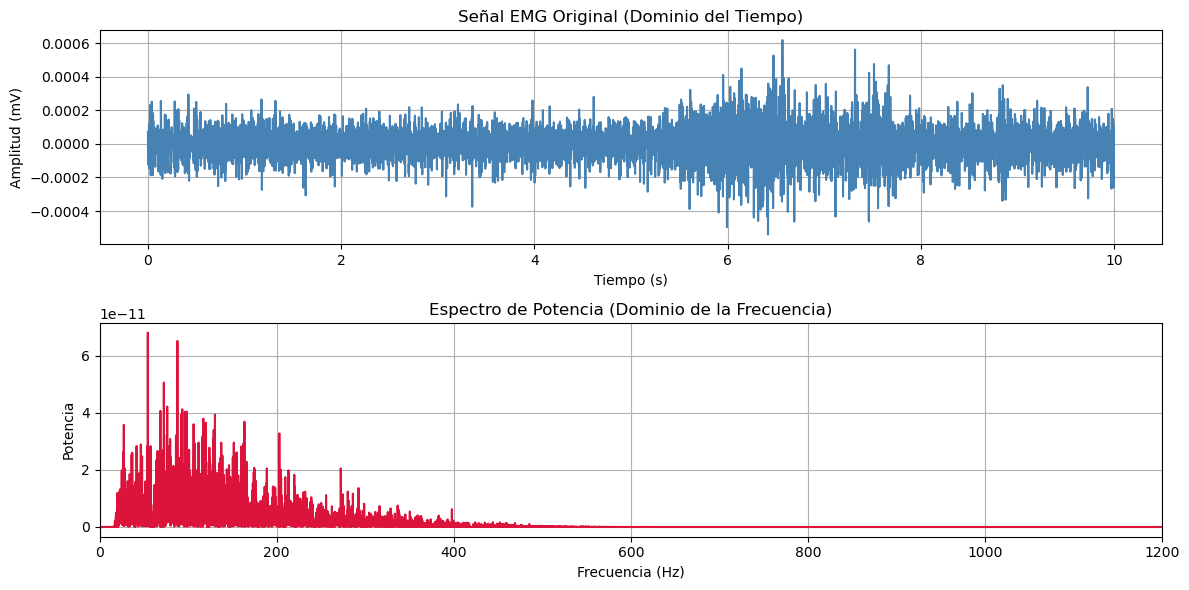

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq
from scipy.signal import find_peaks

def analizar_frecuencia_emg(senal, fs):
    """
    Realiza el análisis FFT de una señal EMG.
    
    Args:
        senal (np.array): Datos de la señal EMG.
        fs (int): Frecuencia de muestreo en Hz.
    """
    n = len(senal)
    
    # 1. Eliminar el componente DC (Centrar la señal)
    senal_centrada = senal - np.mean(senal)
    
    # 2. Calcular la FFT
    # Usamos rfft para señales reales, es más eficiente
    yf = fft(senal_centrada)
    xf = fftfreq(n, 1 / fs)

    # Solo nos interesa la mitad positiva del espectro
    frecuencias = xf[:n // 2]
    amplitud = 2.0 / n * np.abs(yf[:n // 2])
    potencia = amplitud**2

    # 3. Detección de picos prominentes
    # prominence: asegura que el pico destaque sobre el ruido circundante
    # distance: evita detectar múltiples puntos de un mismo pico ancho
    indices_picos, propiedades = find_peaks(potencia, prominence=np.max(potencia)*0.25, distance=10)

    frecuencias_picos = frecuencias[indices_picos]
    potencia_picos = potencia[indices_picos]

    # 4. Graficación
    plt.figure(figsize=(12, 6))

    # Gráfico en el tiempo
    plt.subplot(2, 1, 1)
    tiempo = np.linspace(0, n / fs, n)
    plt.plot(tiempo, senal, color='steelblue')
    plt.title('Señal EMG Original (Dominio del Tiempo)')
    plt.xlabel('Tiempo (s)')
    plt.ylabel('Amplitud (mV)')
    plt.grid(True)

    # Gráfico en frecuencia (Espectro de Potencia)
    plt.subplot(2, 1, 2)
    plt.plot(frecuencias, potencia, color='crimson')

    # Resaltar picos detectados
    # plt.scatter(frecuencias_picos, potencia_picos, color='black', marker='x', s=100, label='Picos Detectados')
    
    # Anotar las frecuencias de los picos más altos
    # for i, freq in enumerate(frecuencias_picos):
    #     plt.annotate(f'{freq:.1f} Hz', (freq, potencia_picos[i]), textcoords="offset points", xytext=(0,10), ha='center', fontsize=9)

    plt.title('Espectro de Potencia (Dominio de la Frecuencia)')
    plt.xlabel('Frecuencia (Hz)')
    plt.ylabel('Potencia')
    plt.xlim(0, fs / 2)  # Límite de Nyquist
    plt.grid(True)

    plt.tight_layout()
    #plt.savefig('analisis_emg_fft.png')
    print("Análisis completado. Gráfica guardada como 'analisis_emg_fft.png'.")

    print(f"Picos detectados en las frecuencias: {frecuencias_picos}")
    return frecuencias_picos, potencia_picos

# Ejemplo de uso con señal sintética
if __name__ == "__main__":
    fs = 2400  # Frecuencia de muestreo típica 1kHz
    t = np.linspace(0, 7, fs)
    # Simulación de EMG: Ruido gaussiano modulado con frecuencias dominantes
    # emg_simulada = 0.5 * np.sin(2 * np.pi * 60 * t) + np.random.normal(0, 0.2, fs)

    emg = data3D_EMG[100,6,:]  # Usar la señal EMG real del primer canal del primer trial
    
    analizar_frecuencia_emg(emg, fs)